# Лабораторная работа №1: Детектирование объектов

**Студент:** Максимова Алина

**Группа:** 6233-010402

**Модель:** YOLOv8 (Ultralytics)

**Датасет:** BDD100K

## Цель
Познакомиться с современными методами детектирования объектов (YOLO, Faster R-CNN), научиться применять предобученные модели и дообучать их на собственных данных.

## Теория
- Object Detection: отличие от классификации и сегментации.
- Архитектуры: YOLO, SSD, Faster R-CNN.
- Метрики: IoU, mAP.

## Задания
1. Выберите одну из моделей (YOLOv8 или Faster R-CNN).
2. Загрузите предобученную модель и примените её к набору изображений (COCO subset, Pascal VOC или небольшой кастомный датасет).
3. Проведите fine-tuning на кастомном датасете (5–10 классов).
4. Оцените качество модели: постройте метрику mAP при разных IoU порогах.
5. Визуализируйте предсказания модели на тестовых изображениях.

## Вопросы
1. Чем one-stage детекторы отличаются от two-stage?
2. Какие ошибки чаще всего допускает модель при детекции?

## Требуемое содержание файла проекта
- Краткий обзор выбранной модели.
- Иллюстрации работы до и после дообучения.
- Графики/таблицы с результатами.
- Ответы на контрольные вопросы.

### Object Detection: отличие от классификации и сегментации
- **Классификация** — определяет класс объекта для всего изображения (один или несколько тегов), без указания местоположения.
- **Object Detection** — находит на изображении объекты и для каждого выдаёт **класс + ограничивающую рамку (bbox) + уверенность**. Может обнаруживать несколько объектов разных классов.
- **Сегментация** — размечает изображение на уровне пикселей: semantic — класс для каждого пикселя, instance — отдельные объекты каждого класса.

### Архитектуры
- **YOLO** — one-stage детектор: за один проход сети предсказывает bbox и классы по сетке/якорям. Быстрый, подходит для real-time.
- **SSD** — one-stage детектор: предсказания на нескольких feature map разного масштаба с default boxes. Хороший баланс скорости и точности.
- **Faster R-CNN** — two-stage детектор: сначала RPN предлагает регионы-кандидаты, затем RoI-голова уточняет bbox и класс. Точный, но обычно медленнее one-stage моделей.

### Метрики
- **IoU** — отношение площади пересечения предсказанного и истинного bbox к площади их объединения. Показывает качество локализации; detection считается верным при IoU ≥ порога.
- **mAP** — средняя точность по классам. Для каждого класса строится precision-recall кривая, считается AP (площадь под кривой), затем усредняется по классам.

## Модель YOLOv8
### Общее описание
YOLOv8 — это модель для обнаружения объектов. Она развивает идеи предыдущих версий YOLO, в ней улучшили баланс между скоростью, точностью и простотой использования. YOLOv8 является one-stage детектором, что делает её подходящей для задач реального времени.

## Ключевые архитектурные особенности

*   Anchor-Free дизайн
*   Архитектура использует разделяемую голову, в которой задачи классификации, регрессии рамок и определения объекта (objectness) обрабатываются независимо.
*   Mодуль C2f улучшает поток информации и объединяет признаки высокого уровня с контекстной информацией, что особенно полезно для обнаружения мелких объектов.
*   Модель использует несколько карт признаков разного масштаба, что позволяет эффективно обнаруживать объекты различных размеров.


## Многофункциональность
Помимо обнаружения объектов, YOLOv8 поддерживает широкий спектр задач компьютерного зрения, включая сегментацию экземпляров, классификацию изображений и оценку позы.

## Режимы использования

1. **Train** - oбучение модели на пользовательском наборе данных.

2. **Val** - валидация модели.

3. **Predict** - инференс на новых изображениях или видео.

4. **Export** - экспорт модели в различные форматы для развёртывания.

## Установка зависимостей

In [ ]:
# установка kagglehub для скачивания датасета
!pip install -q kagglehub

In [ ]:
# установка библиотеки YOLOv8
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## Скачивание датасета

In [ ]:
import kagglehub
import os

# скачивание датасета
path = kagglehub.dataset_download("a7madmostafa/bdd100k-yolo")
print("Датасет скачан по пути:", path)

# проверка структуры и пути к data.yaml
dataset_dir = os.path.join(path, "bdd100k_yolo")
# если внутри есть папка bdd100k_yolo, используем её
if not os.path.exists(dataset_dir):
    dataset_dir = path

yaml_path = os.path.join(dataset_dir, "data.yaml")
print("Путь к data.yaml:", yaml_path)

# вывод содержимого data.yaml
if os.path.exists(yaml_path):
    with open(yaml_path, "r") as f:
        print(f.read())
else:
    print("Файл data.yaml не найден. Проверьте структуру папок.")

100%|██████████| 5.33G/5.33G [04:38<00:00, 20.5MB/s]

Extracting files...


Датасет скачан по пути: /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4
Путь к data.yaml: /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/data.yaml
path: /kaggle/input/bdd100k-yolo
train: /kaggle/input/bdd100k-yolo/train/images
val: /kaggle/input/bdd100k-yolo/val/images
test: /kaggle/input/bdd100k-yolo/test/images

nc: 10
names:
  - person
  - rider
  - car
  - bus
  - truck
  - bike
  - motor
  - traffic light
  - traffic sign
  - train



## Датасет

BDD100K —  датасет для задач автономного вождения, содержащий 100 000 аннотации дорожных сцен в США.

Содержит 10 классов.

## Инференс предобученной модели

In [ ]:
import os
import random
import kagglehub
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import yaml
from IPython.display import Image, display
import numpy as np
import glob


Датасет скачан по пути: /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4
Файл data.yaml успешно обновлен правильными путями

Запуск инференса...
Выбрано 6 случайных изображений для инференса.

Изображение 1/6: 5198025d-29be59bd.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/5198025d-29be59bd.jpg: 384x640 4 persons, 3 cars, 1 bus, 7.2ms
Speed: 1.7ms preprocess, 7.2ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


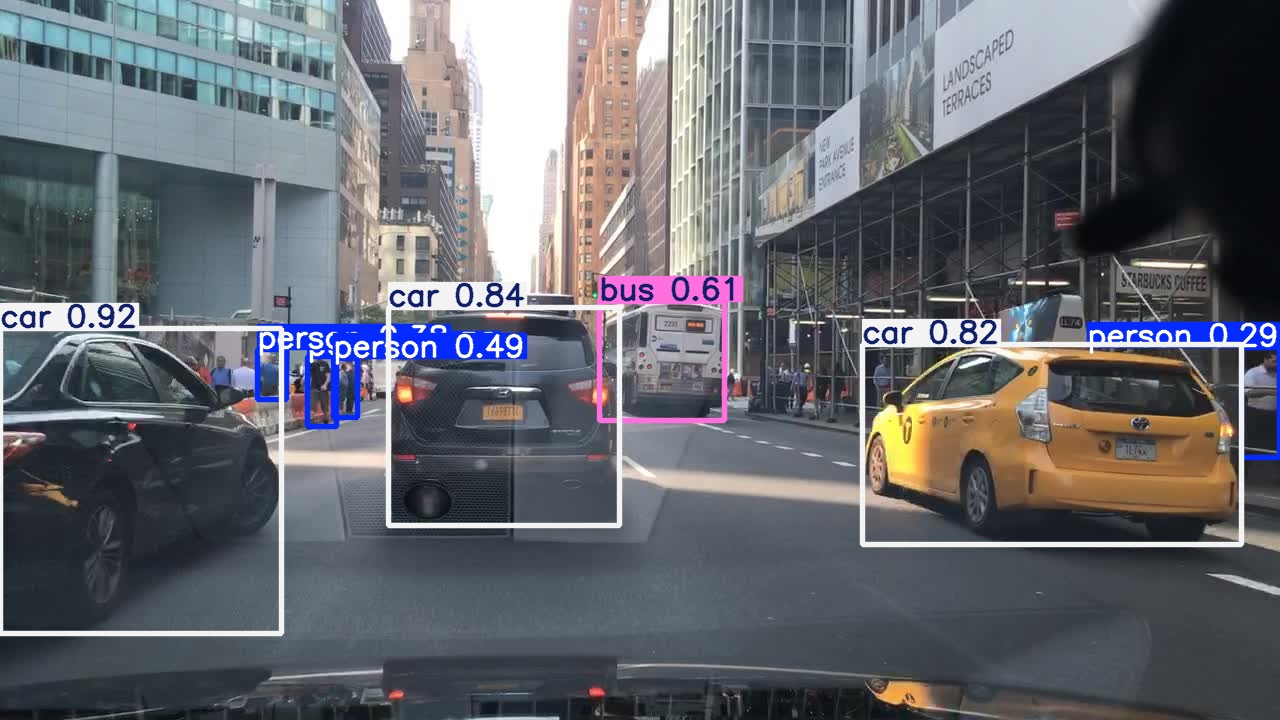

Найдено объектов: 8
  - car             (уверенность: 0.92)
  - car             (уверенность: 0.84)
  - car             (уверенность: 0.82)
  - bus             (уверенность: 0.61)
  - person          (уверенность: 0.49)
  - person          (уверенность: 0.38)
  - person          (уверенность: 0.38)
  - person          (уверенность: 0.29)


Изображение 2/6: a118fb8c-5779d180.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/a118fb8c-5779d180.jpg: 384x640 11 cars, 17.5ms
Speed: 1.8ms preprocess, 17.5ms inference, 3.1ms postprocess per image at shape (1, 3, 384, 640)


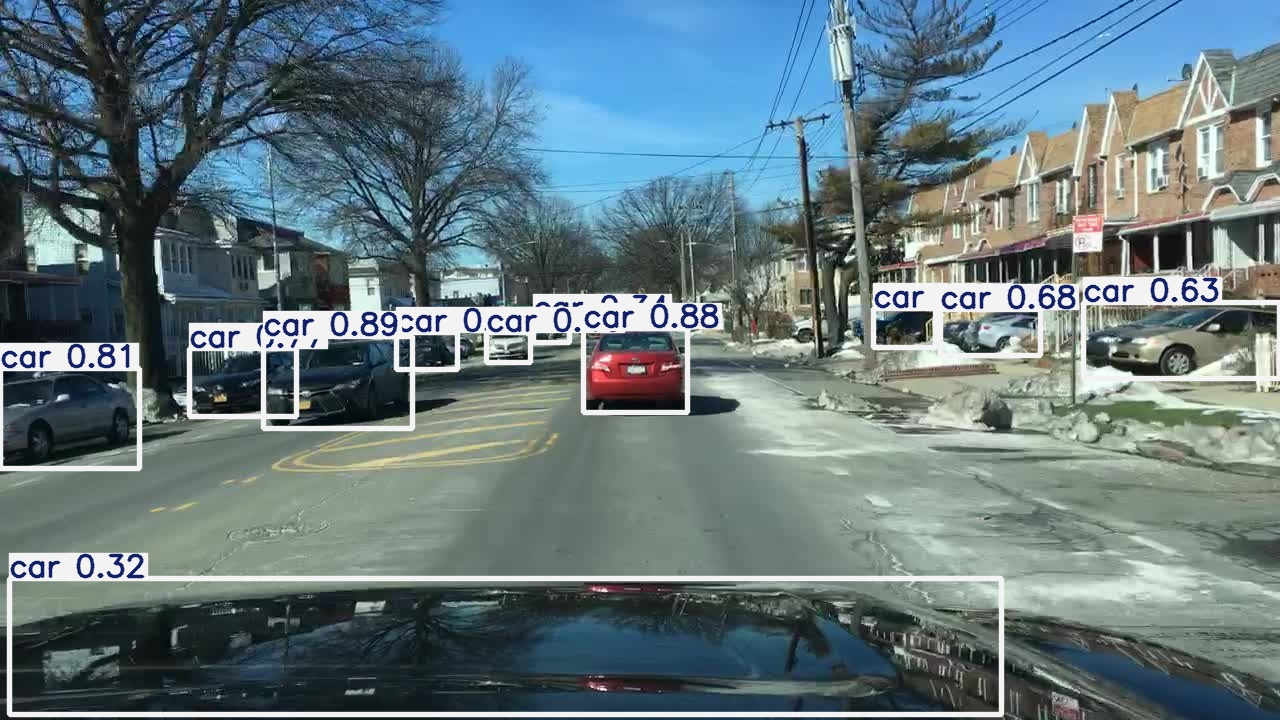

Найдено объектов: 11
  - car             (уверенность: 0.89)
  - car             (уверенность: 0.88)
  - car             (уверенность: 0.81)
  - car             (уверенность: 0.77)
  - car             (уверенность: 0.68)
  - car             (уверенность: 0.63)
  - car             (уверенность: 0.46)
  - car             (уверенность: 0.34)
  - car             (уверенность: 0.34)
  - car             (уверенность: 0.32)
  - car             (уверенность: 0.27)


Изображение 3/6: 28ad955f-0627393c.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/28ad955f-0627393c.jpg: 384x640 5 cars, 1 truck, 14.0ms
Speed: 1.5ms preprocess, 14.0ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)


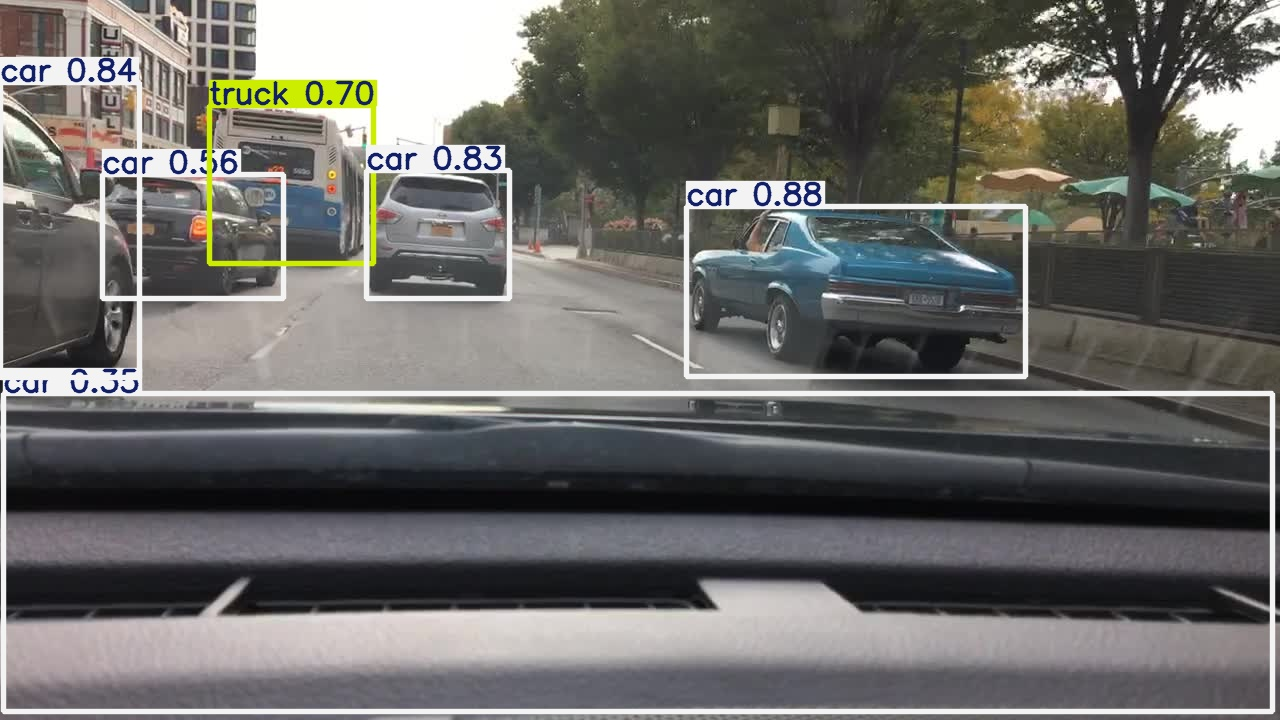

Найдено объектов: 6
  - car             (уверенность: 0.88)
  - car             (уверенность: 0.84)
  - car             (уверенность: 0.83)
  - truck           (уверенность: 0.70)
  - car             (уверенность: 0.56)
  - car             (уверенность: 0.35)


Изображение 4/6: a68885a4-0972e57a.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/a68885a4-0972e57a.jpg: 384x640 1 car, 2 traffic lights, 15.3ms
Speed: 1.5ms preprocess, 15.3ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)


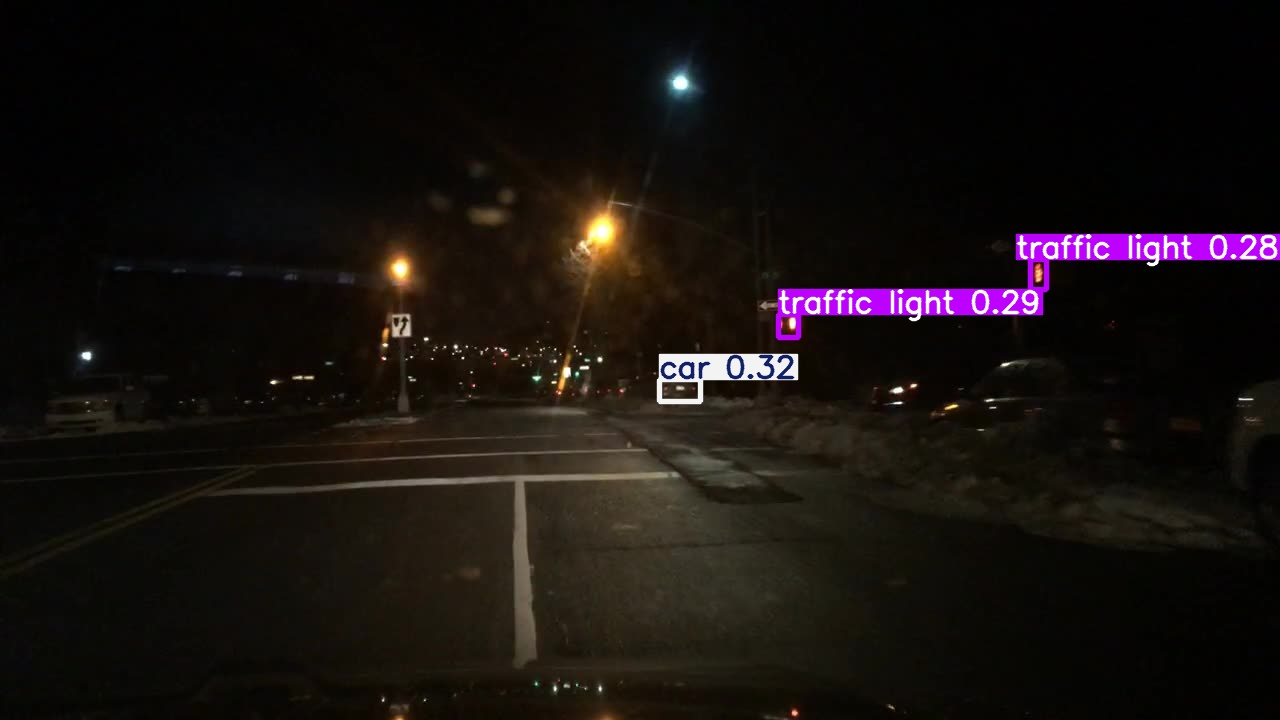

Найдено объектов: 3
  - car             (уверенность: 0.32)
  - traffic light   (уверенность: 0.29)
  - traffic light   (уверенность: 0.28)


Изображение 5/6: 67a1498c-119fe159.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/67a1498c-119fe159.jpg: 384x640 2 cars, 11.9ms
Speed: 3.5ms preprocess, 11.9ms inference, 2.5ms postprocess per image at shape (1, 3, 384, 640)


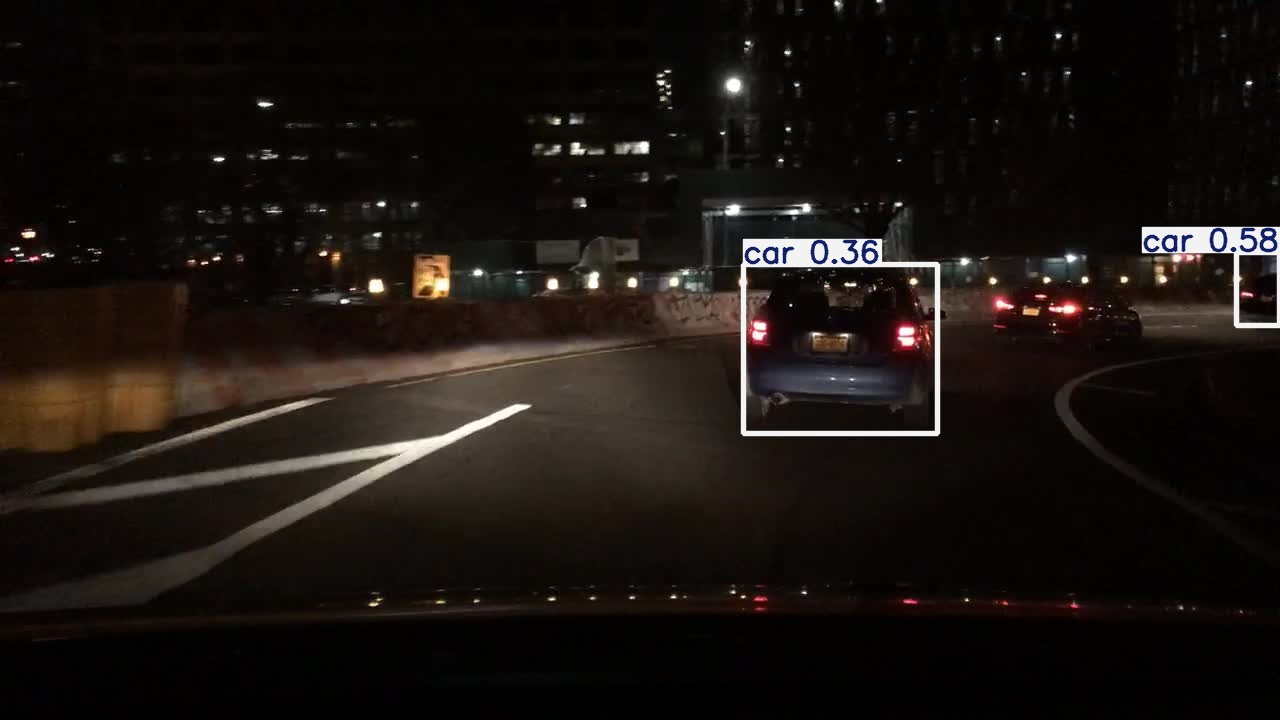

Найдено объектов: 2
  - car             (уверенность: 0.58)
  - car             (уверенность: 0.36)


Изображение 6/6: 087f969b-b1584c3f.jpg

image 1/1 /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/train/images/087f969b-b1584c3f.jpg: 384x640 11 cars, 9.9ms
Speed: 3.7ms preprocess, 9.9ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


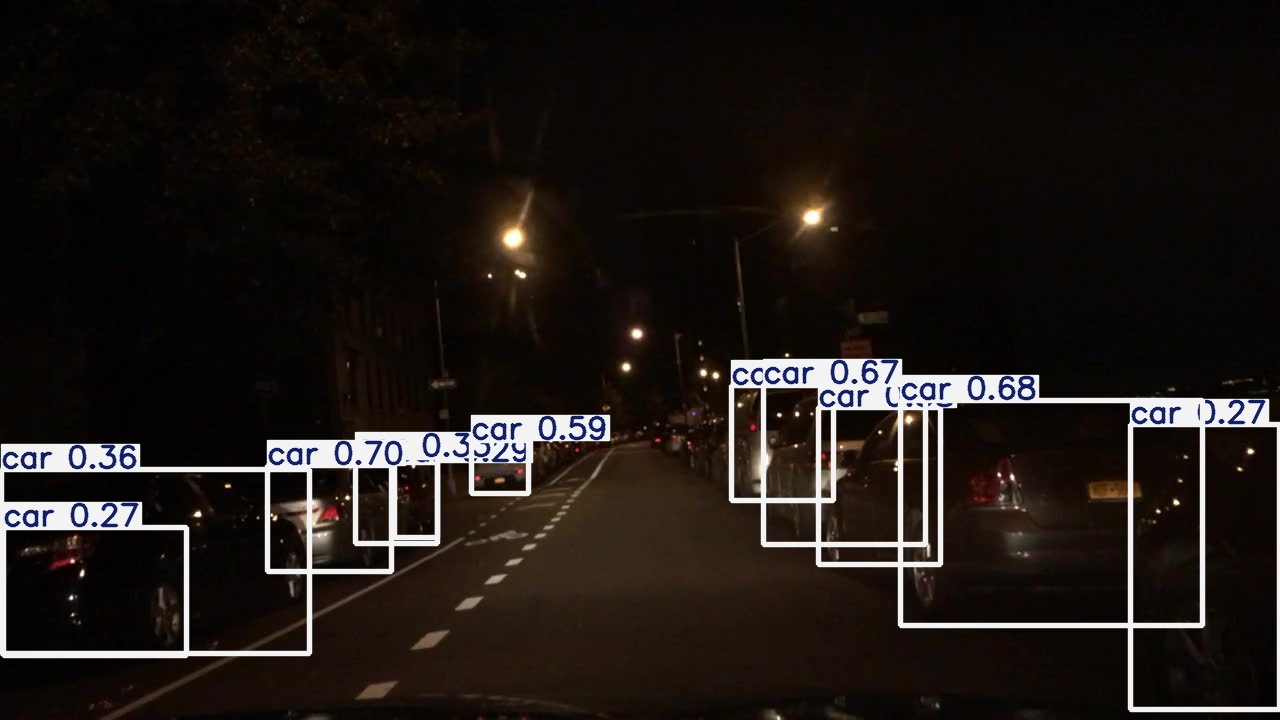

Найдено объектов: 11
  - car             (уверенность: 0.70)
  - car             (уверенность: 0.68)
  - car             (уверенность: 0.67)
  - car             (уверенность: 0.59)
  - car             (уверенность: 0.58)
  - car             (уверенность: 0.36)
  - car             (уверенность: 0.33)
  - car             (уверенность: 0.29)
  - car             (уверенность: 0.29)
  - car             (уверенность: 0.27)
  - car             (уверенность: 0.27)




In [ ]:
# путь датасета (из кеша, т.к. уже скачан)
path = kagglehub.dataset_download("a7madmostafa/bdd100k-yolo")
print("Датасет скачан по пути:", path)

# определяем правильную папку
dataset_dir = os.path.join(path, "bdd100k_yolo")
if not os.path.exists(dataset_dir):
    dataset_dir = path

yaml_path = os.path.join(dataset_dir, "data.yaml")

# перезапись пути в data.yaml на актуальные для Colab
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        yaml_data = yaml.safe_load(f)

    yaml_data['path'] = dataset_dir
    yaml_data['train'] = os.path.join(dataset_dir, 'train', 'images')
    yaml_data['val'] = os.path.join(dataset_dir, 'val', 'images')
    yaml_data['test'] = os.path.join(dataset_dir, 'test', 'images')

    with open(yaml_path, 'w') as f:
        yaml.dump(yaml_data, f)
    print("Файл data.yaml успешно обновлен правильными путями")
else:
    print("Файл data.yaml не найден")


# инференс предобученной модели
print("\nЗапуск инференса...")
model = YOLO("yolov8n.pt")

train_images_path = os.path.join(dataset_dir, "train", "images")

# проверка, что папка есть и в ней достаточно картинок
if os.path.exists(train_images_path) and len(os.listdir(train_images_path)) >= 6:
    all_images = os.listdir(train_images_path)

    # Проверяем, чтобы не схватить скрытые файлы
    all_images = [img for img in all_images if img.endswith(('.jpg', '.jpeg', '.png'))]

    # Выбираем 6 случайных уникальных картинок
    random_images = random.sample(all_images, 6)

    print(f"Выбрано 6 случайных изображений для инференса.\n")

    # цикл по выбранным картинкам
    for i, image_name in enumerate(random_images):
        image_path = os.path.join(train_images_path, image_name)
        print(f"Изображение {i+1}/6: {image_name}")

        # запуск инференса
        results = model(image_path)

        # сохраняем результат
        output_filename = f"bdd_test_result_{i+1}.jpg"
        results[0].save(filename=output_filename)

        # вывод картинки
        display(Image(filename=output_filename))

        # текстовая информация о найденных объектах
        boxes = results[0].boxes
        if len(boxes) > 0:
            print(f"Найдено объектов: {len(boxes)}")
            for box in boxes:
                cls_id = int(box.cls[0])
                class_name = model.names[cls_id]
                confidence = float(box.conf[0])
                print(f"  - {class_name:<15} (уверенность: {confidence:.2f})")
        else:
            print("Объекты не найдены.")
        print("\n")

else:
    print(f"Ошибка: Папка {train_images_path} не найдена или содержит меньше 6 картинок.")
    print(f"Проверьте содержимое папки: {dataset_dir}")

Использована предобученная на COCO модель YOLOv8n (yolov8n.pt), применённая к выборке из 6 изображений кастомного датасета BDD100K (YOLO-формат), загруженного с Kaggle

**Результат:** модель распознала только самые основные объекты.

## Fine-tuning

In [ ]:
# Загружаем модель
model = YOLO("yolov8n.pt")

# Запуск fine-tuning
print("Начинаем fine-tuning...")
results = model.train(
    data=yaml_path,
    epochs=10,
    imgsz=640,
    batch=32,
    cache='ram',
    workers=8,
    amp=True,
    cos_lr=True,
    close_mosaic=10,
    pretrained=True,
    name='bdd_finetune'
)
print("\nFine-tuning завершен!")

Начинаем fine-tuning...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale

## Метрика mAP при разных IoU порогах

Запуск оценки качества
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 970.0±435.7 MB/s, size: 67.3 KB)
val: Scanning /root/.cache/kagglehub/datasets/a7madmostafa/bdd100k-yolo/versions/4/val/labels.cache... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000 1.4Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 625/625 6.4it/s 1:37
                   all      10000     185578       0.64      0.384      0.415      0.224
                person       3220      13265      0.655      0.429      0.487      0.225
                 rider        515        649      0.485      0.273      0.297      0.138
                   car       9879     102540      0.707      0.675      0.714       0.43
                   bus       1242       1597      0.605   

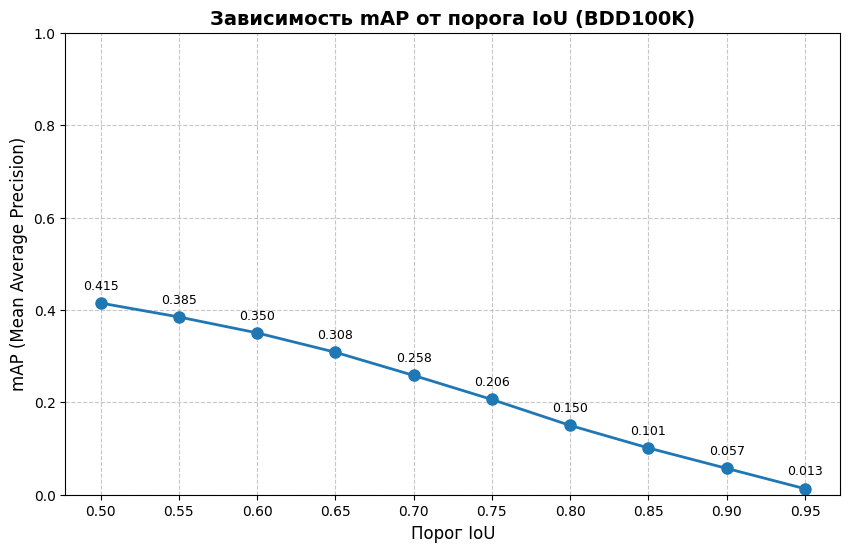

In [ ]:
# пути
path = kagglehub.dataset_download("a7madmostafa/bdd100k-yolo")
dataset_dir = os.path.join(path, "bdd100k_yolo") if os.path.exists(os.path.join(path, "bdd100k_yolo")) else path
yaml_path = os.path.join(dataset_dir, "data.yaml")

# загрузка модели и валидация
best_model_path = "/content/runs/detect/bdd_finetune-2/weights/best.pt"
trained_model = YOLO(best_model_path)

print("Запуск оценки качества")
metrics = trained_model.val(data=yaml_path)

# 10 точек mAP для разных порогов IoU
iou_thresholds = np.linspace(0.5, 0.95, 10)
map_per_iou = metrics.box.all_ap.mean(axis=0)

# вывод всех 10 точек в консоль
print("\n")
print("Результаты: mAP при разных порогах IoU")
print("\n")
for i in range(10):
    print(f"IoU = {iou_thresholds[i]:.2f}  ->  mAP = {map_per_iou[i]:.4f}")

# Выводим общие метрики для справки
print(f"mAP@0.5 (IoU=0.50):       {metrics.box.map50:.4f}")
print(f"mAP@0.75 (IoU=0.75):      {metrics.box.map75:.4f}")
print(f"mAP@0.5:0.95 (Среднее):   {metrics.box.map:.4f}")

# график
plt.figure(figsize=(10, 6))

# линия с маркерами
plt.plot(iou_thresholds, map_per_iou, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=8)

for i, txt in enumerate(map_per_iou):
    plt.annotate(f"{txt:.3f}", (iou_thresholds[i], map_per_iou[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

# оси и заголовок
plt.title('Зависимость mAP от порога IoU (BDD100K)', fontsize=14, fontweight='bold')
plt.xlabel('Порог IoU', fontsize=12)
plt.ylabel('mAP (Mean Average Precision)', fontsize=12)
plt.xticks(iou_thresholds)
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0, 1.0)

# Показываем график
plt.show()

**Оценка результата:**
График показывает, как меняется точность (mAP) при ужесточении требований к точности координат (IoU).

Порог IoU показывает, насколько точно предсказанная рамка должна совпадать с реальной, где IoU = 0.50 - рамка просто «попадает» в объект (пересечение больше 50%), а IoU = 0.95 - рамка должна совпадать почти идеально, пиксель в пиксель.mAP же это общая точность модели.

График падает из-за того, что чем строже требуется от модели точность рамки (выше IoU), тем ниже становится метрика точности. Таким образом, закономерно ожидать, что график упадет.



---



**Причины плохого результата**

1. Специфика датасета. BDD100K — это датасет, в котором огромное количество ночных снимков, дождя, бликов, размытых фар, объектов, перекрывающих друг друга, и очень маленьких объектов (например, пешеходов вдалеке). Модели сложно ставить идеальные рамки на таких фото, так как в большинстве своем они размытые и темные.

2. yolov8n (Nano) — это самая маленькая и быстрая версия. Она жертвует точностью локализации (постановки рамок) ради скорости. Для узких рамок (IoU > 0.75) ей просто не хватает количества параметров.

3. Повтороно специфика датасета. Из-за того, что датасет состоит из большого количества темных и размытых снимков нормой считается, что для BDD100K требуется 50–100 эпох, чтобы модель «набила руку» и научилась ставить рамки точнее, когда здесь модель была обучена всего на 10 эпохах.

## Результаты

Найдена папка с результатами: runs/detect/val

Матрица ошибок (Confusion Matrix)


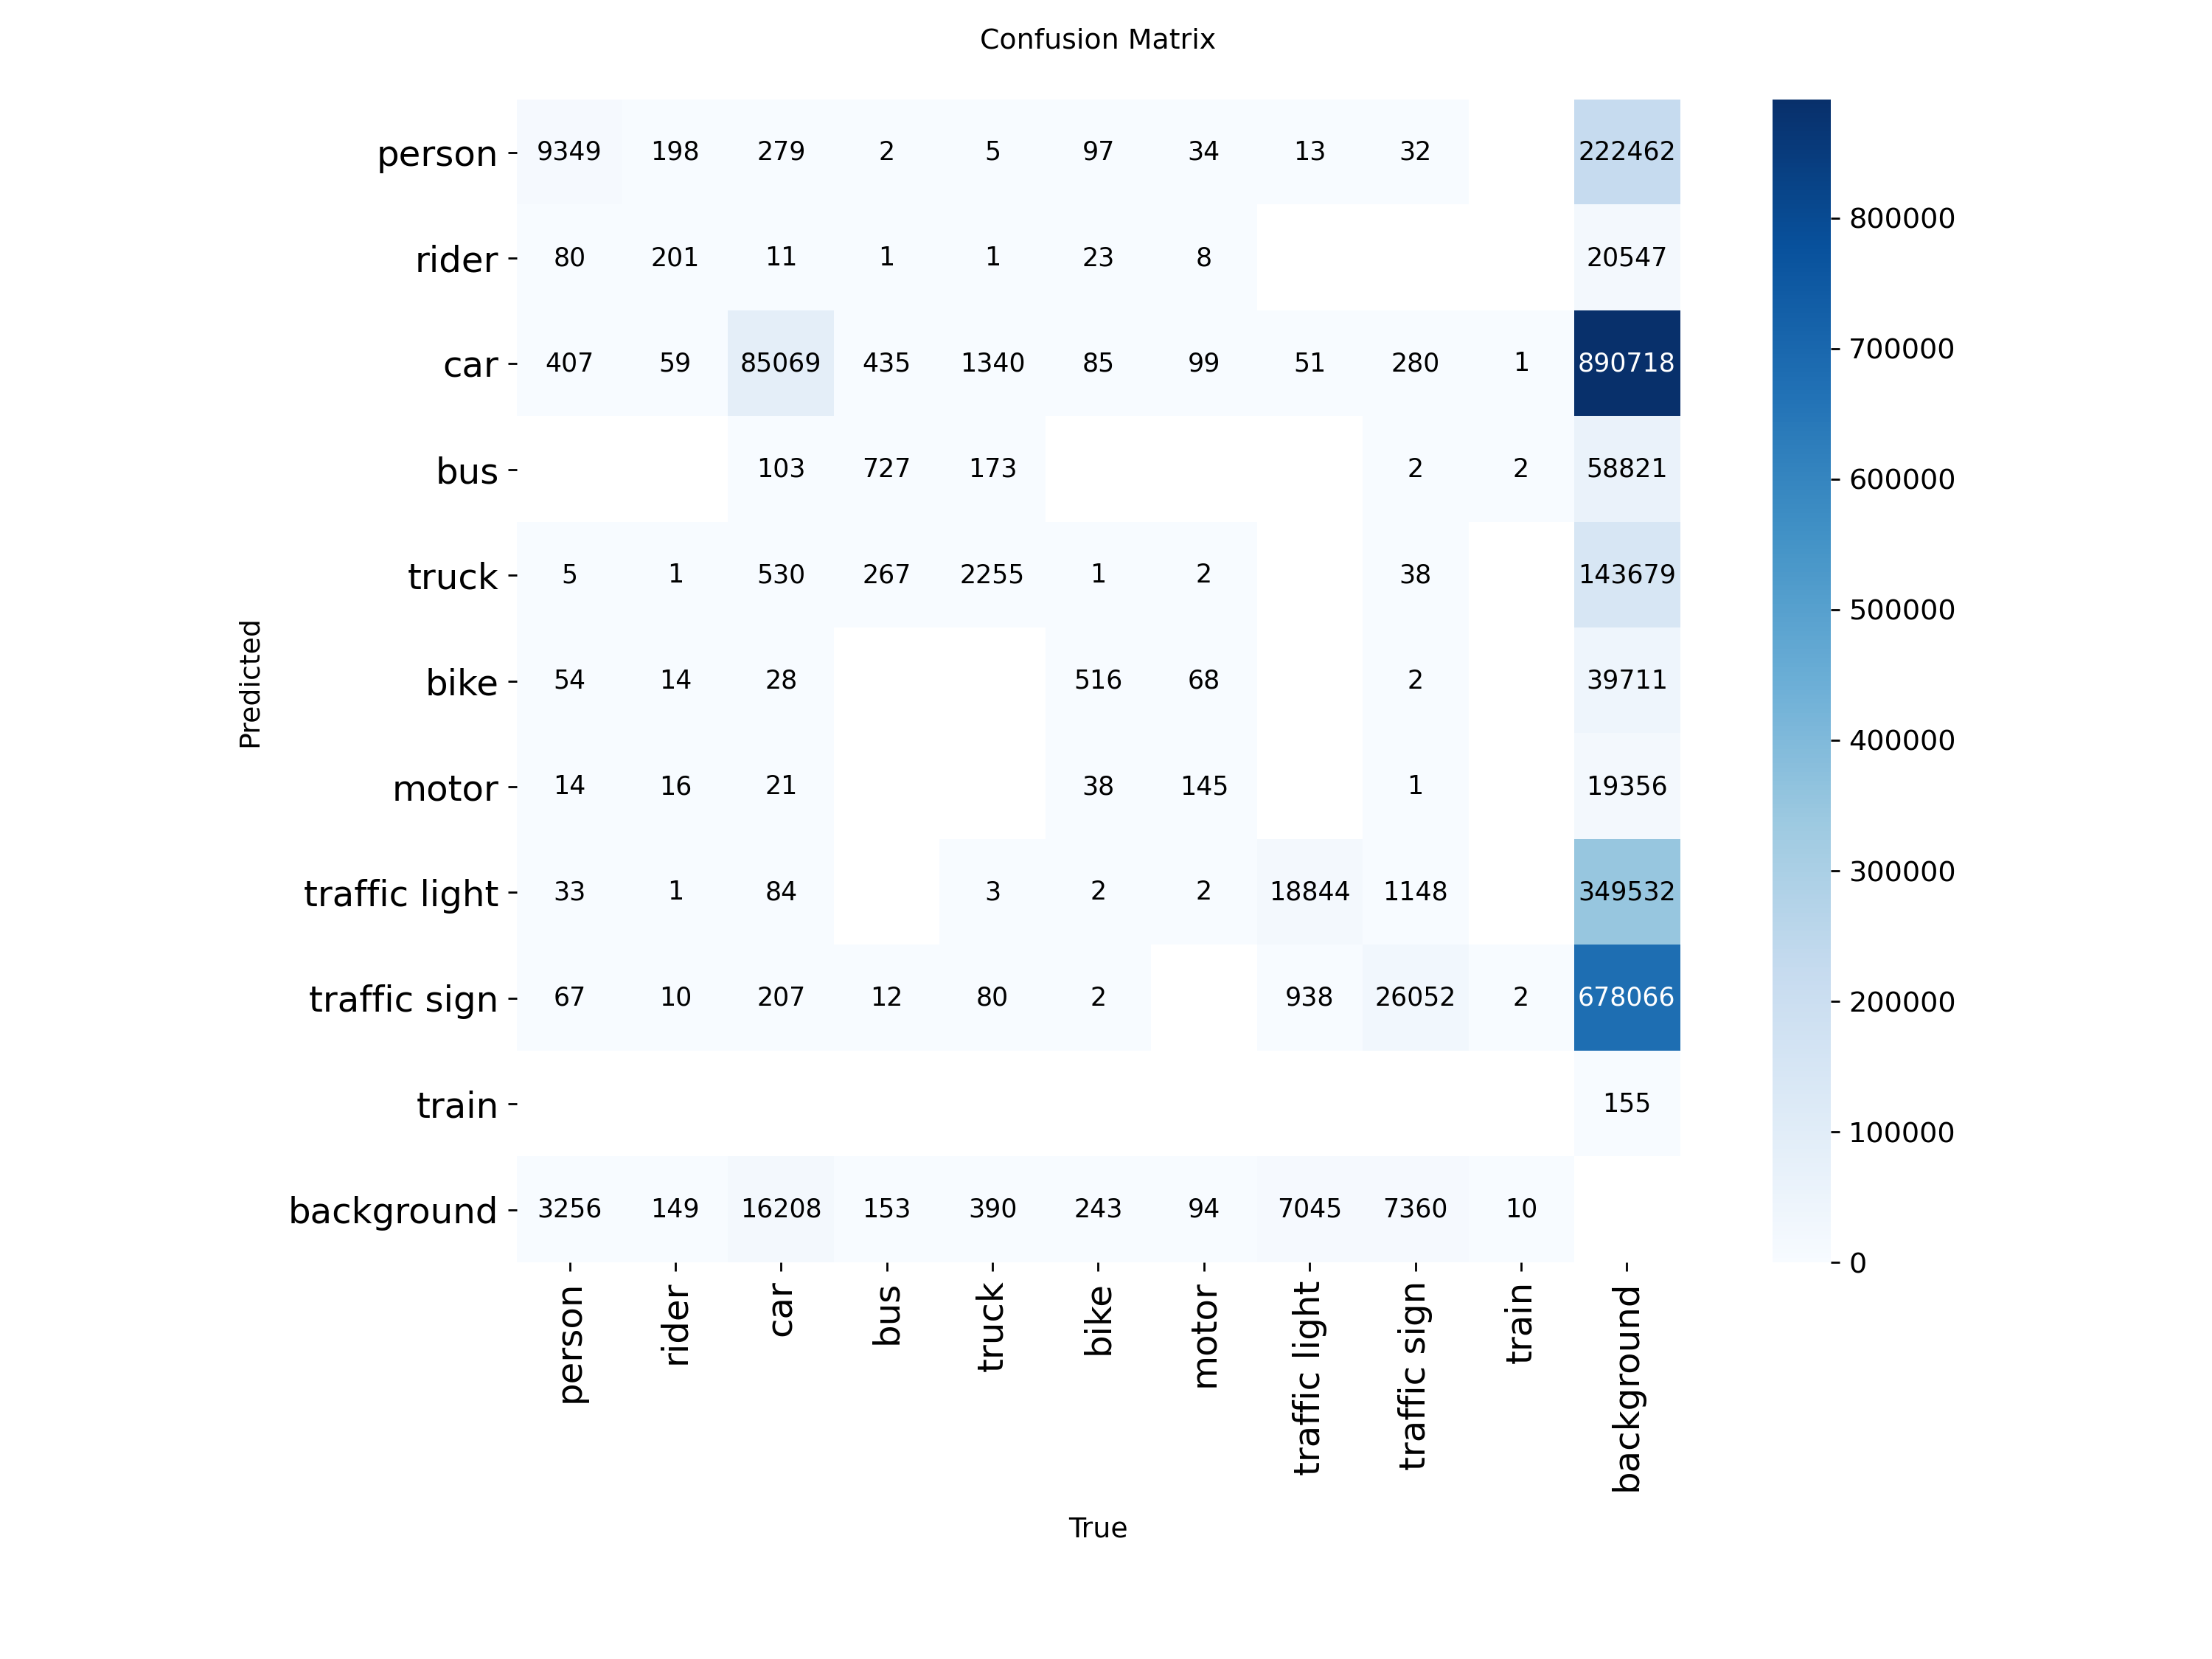



Нормализованная матрица ошибок


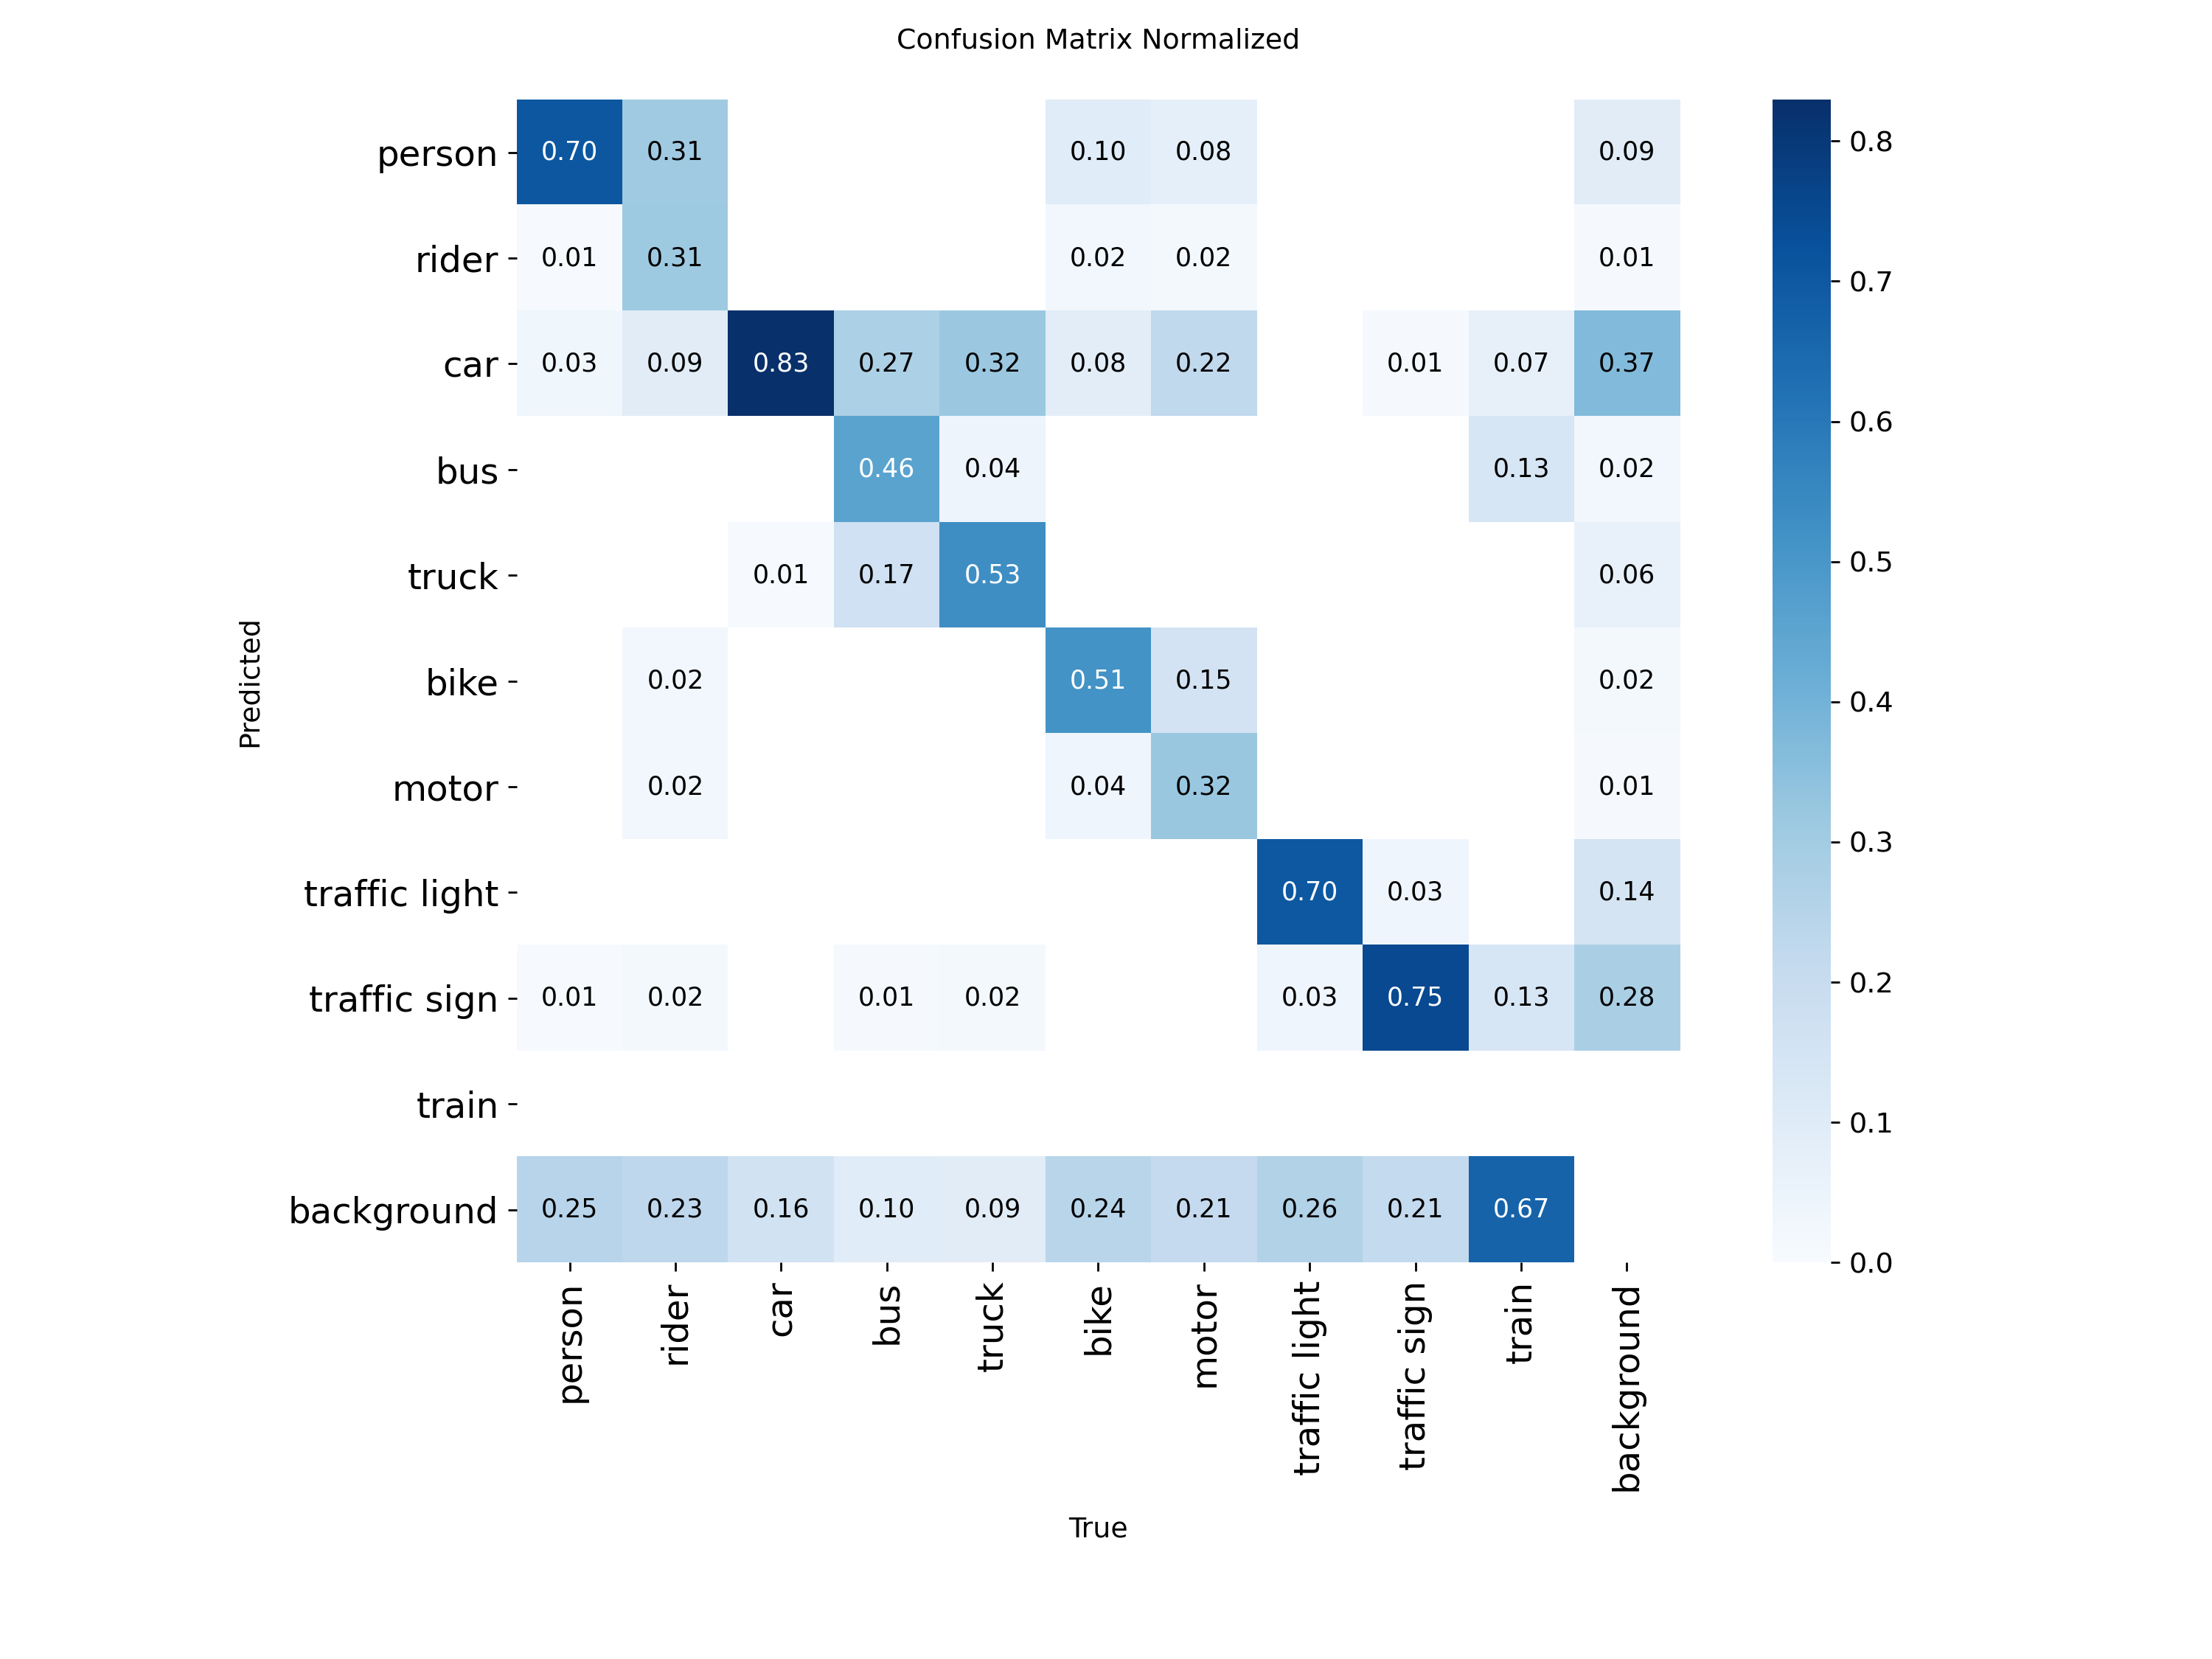



Пример предсказаний на валидационном батче


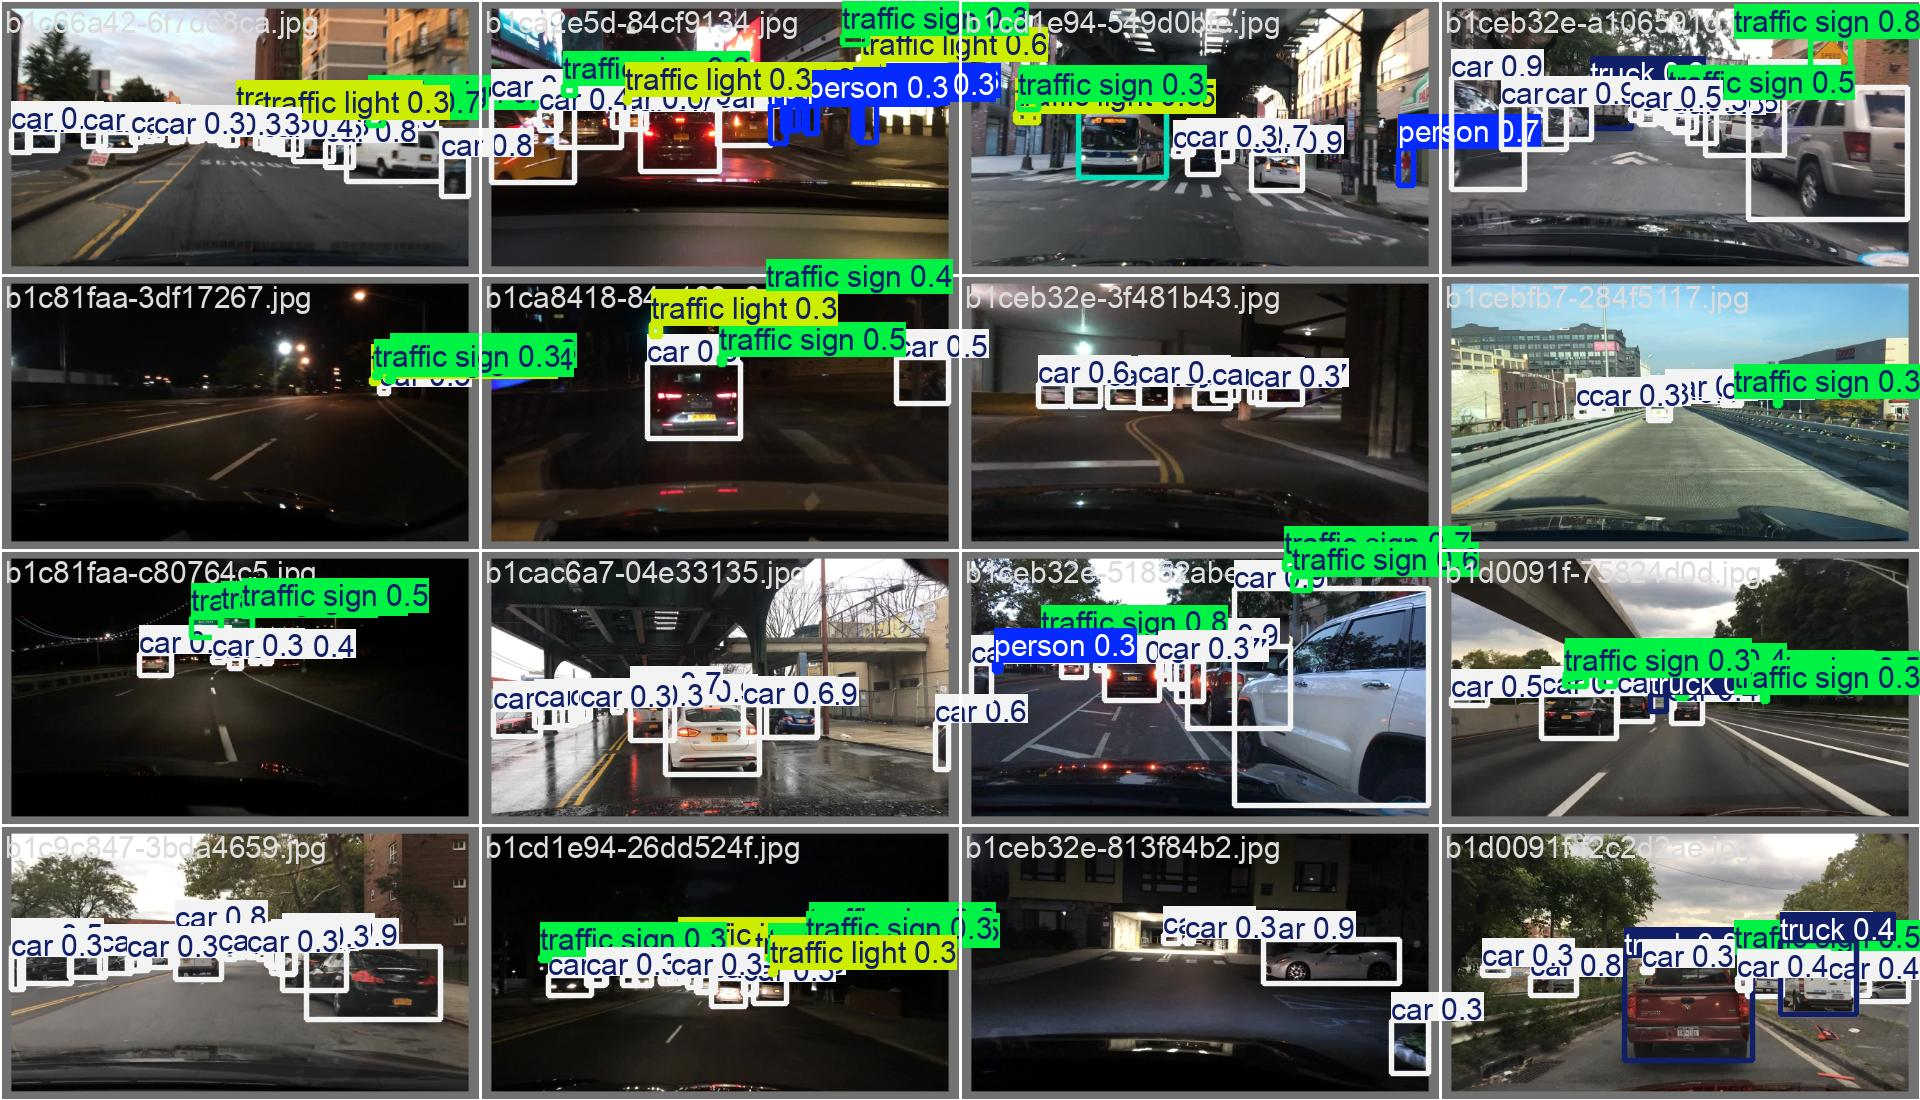



Реальные метки (Ground Truth) на том же батче


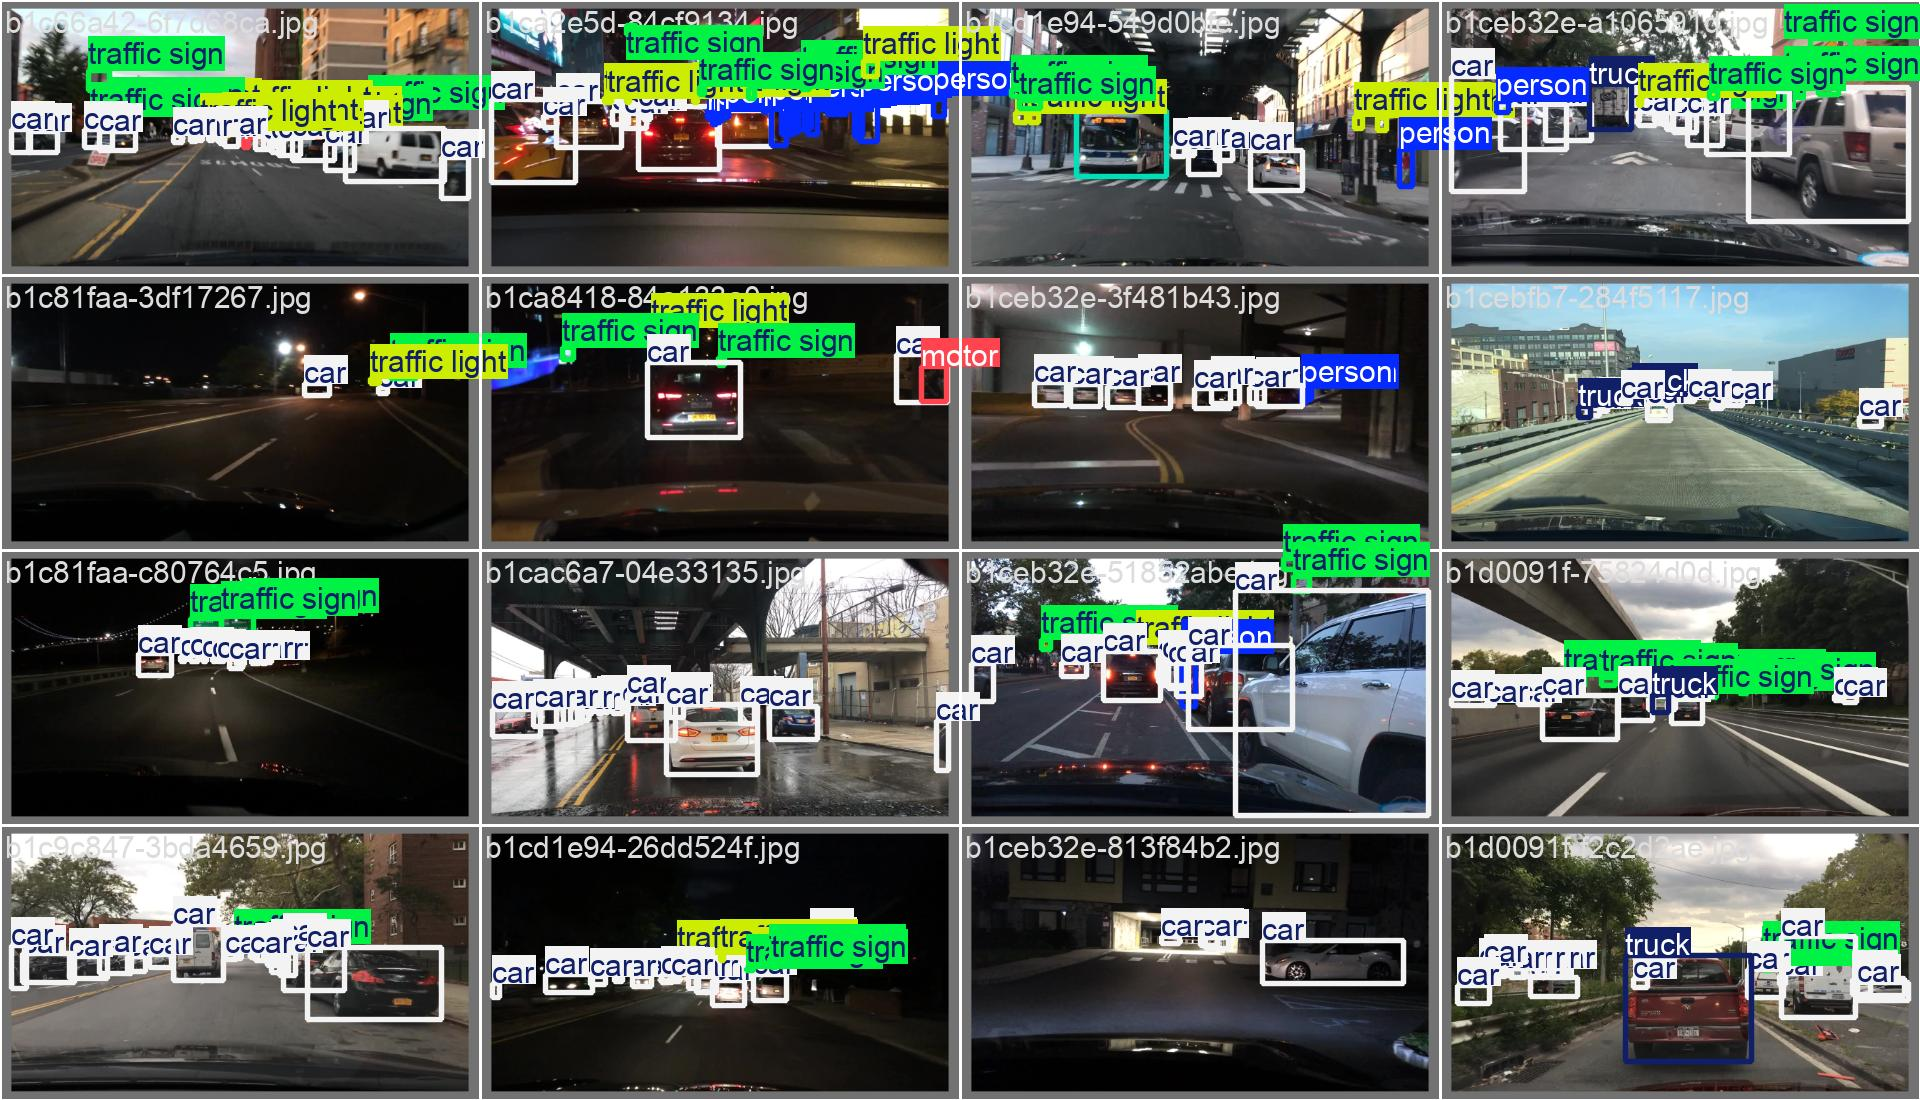

In [ ]:
# папка с результатами валидации
val_dirs = glob.glob("runs/detect/val*")
if not val_dirs:
    print("Папка с результатами валидации не найдена")
else:
    # Сортировка по времени изменения, чтобы взять самую последнюю
    latest_val_dir = max(val_dirs, key=os.path.getmtime)
    print(f"Найдена папка с результатами: {latest_val_dir}\n")

    # Список графиков
    plots_to_show = [
        ("confusion_matrix.png", "Матрица ошибок (Confusion Matrix)"),
        ("confusion_matrix_normalized.png", "Нормализованная матрица ошибок"),
        ("PR_curve.png", "Precision-Recall кривая (PR Curve)"),
        ("F1_curve.png", "Кривая F1-score (зависимость от порога уверенности)"),
        ("P_curve.png", "Кривая Precision (Точность)"),
        ("R_curve.png", "Кривая Recall (Полнота)"),
        ("labels.jpg", "Распределение классов и боксов в датасете"),
        ("val_batch0_pred.jpg", "Пример предсказаний на валидационном батче"),
        ("val_batch0_labels.jpg", "Реальные метки (Ground Truth) на том же батче")
    ]

    # выводим графики
    for filename, title in plots_to_show:
        file_path = os.path.join(latest_val_dir, filename)

        if os.path.exists(file_path):
            print(f"{title}")
            display(Image(filename=file_path, width=800))
            print("\n")
        else:
            pass

## Визуализация предсказаний после fine-tuning

Using Colab cache for faster access to the 'bdd100k-yolo' dataset.
Изображение 1/6: f2381bad-c8fa03bd.jpg

image 1/1 /kaggle/input/bdd100k-yolo/test/images/f2381bad-c8fa03bd.jpg: 384x640 12 cars, 11 traffic lights, 7.4ms
Speed: 17.6ms preprocess, 7.4ms inference, 21.6ms postprocess per image at shape (1, 3, 384, 640)


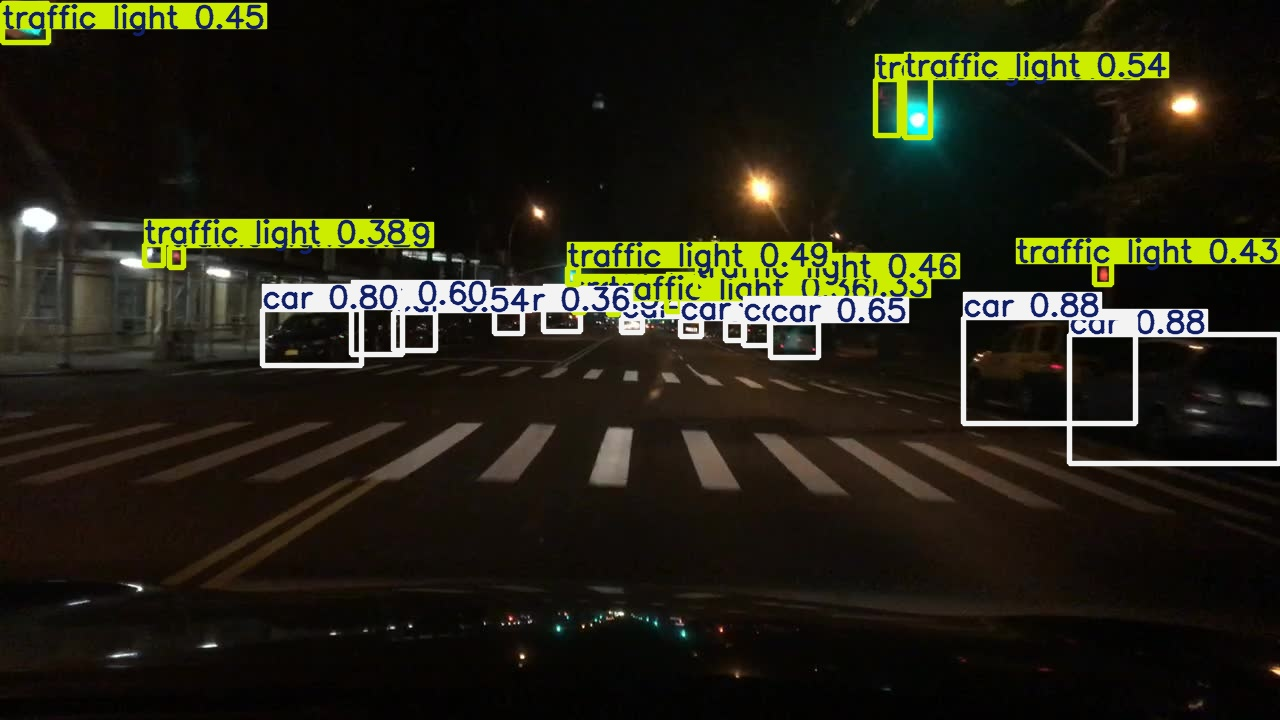

Найдено объектов: 23
  - car             (уверенность: 0.88)
  - car             (уверенность: 0.88)
  - car             (уверенность: 0.80)
  - car             (уверенность: 0.65)
  - car             (уверенность: 0.60)
  - traffic light   (уверенность: 0.54)
  - car             (уверенность: 0.54)
  - traffic light   (уверенность: 0.49)
  - traffic light   (уверенность: 0.46)
  - car             (уверенность: 0.45)
  - traffic light   (уверенность: 0.45)
  - traffic light   (уверенность: 0.45)
  - traffic light   (уверенность: 0.43)
  - traffic light   (уверенность: 0.38)
  - car             (уверенность: 0.36)
  - traffic light   (уверенность: 0.36)
  - car             (уверенность: 0.35)
  - traffic light   (уверенность: 0.35)
  - traffic light   (уверенность: 0.33)
  - car             (уверенность: 0.32)
  - car             (уверенность: 0.30)
  - traffic light   (уверенность: 0.29)
  - car             (уверенность: 0.27)


Изображение 2/6: e537a7ff-2dc77166.jpg

image 1/1 /kaggle

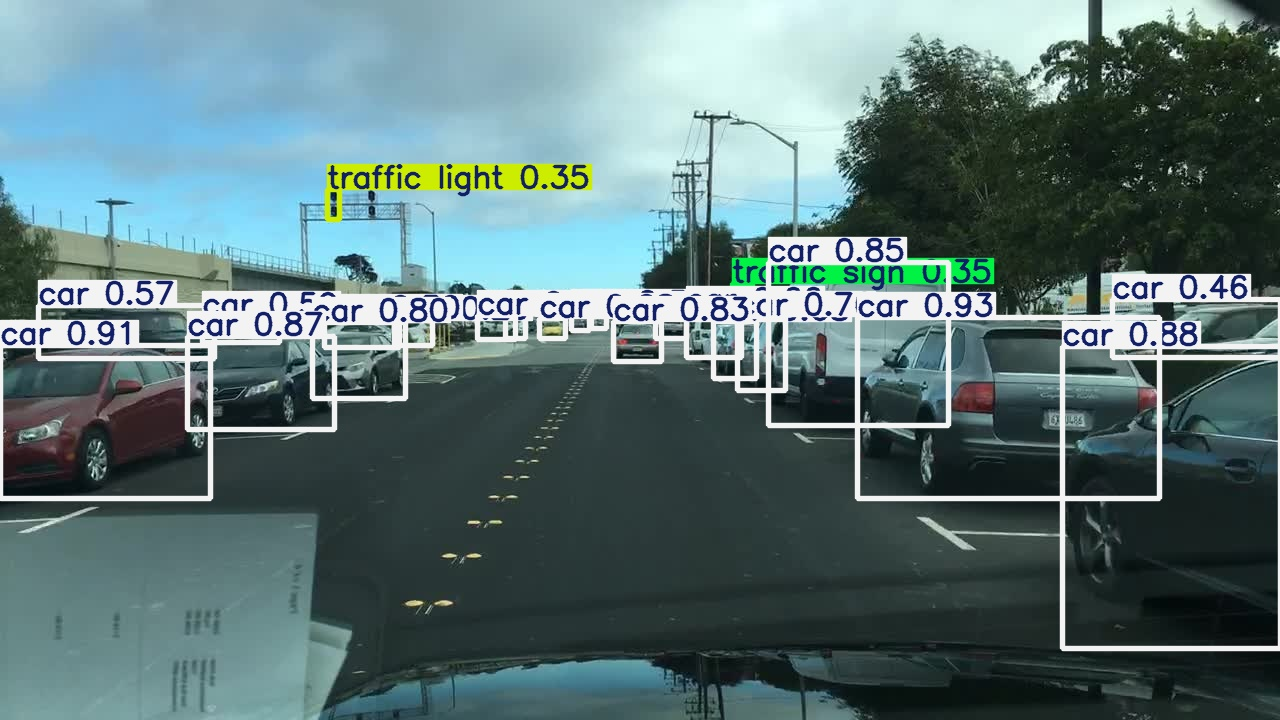

Найдено объектов: 23
  - car             (уверенность: 0.93)
  - car             (уверенность: 0.91)
  - car             (уверенность: 0.88)
  - car             (уверенность: 0.87)
  - car             (уверенность: 0.85)
  - car             (уверенность: 0.83)
  - car             (уверенность: 0.80)
  - car             (уверенность: 0.76)
  - car             (уверенность: 0.68)
  - car             (уверенность: 0.68)
  - car             (уверенность: 0.66)
  - car             (уверенность: 0.59)
  - car             (уверенность: 0.57)
  - car             (уверенность: 0.54)
  - car             (уверенность: 0.46)
  - traffic sign    (уверенность: 0.35)
  - traffic light   (уверенность: 0.35)
  - car             (уверенность: 0.35)
  - car             (уверенность: 0.34)
  - car             (уверенность: 0.30)
  - car             (уверенность: 0.29)
  - car             (уверенность: 0.29)
  - car             (уверенность: 0.27)


Изображение 3/6: fbc3759e-56fec0f7.jpg

image 1/1 /kaggle

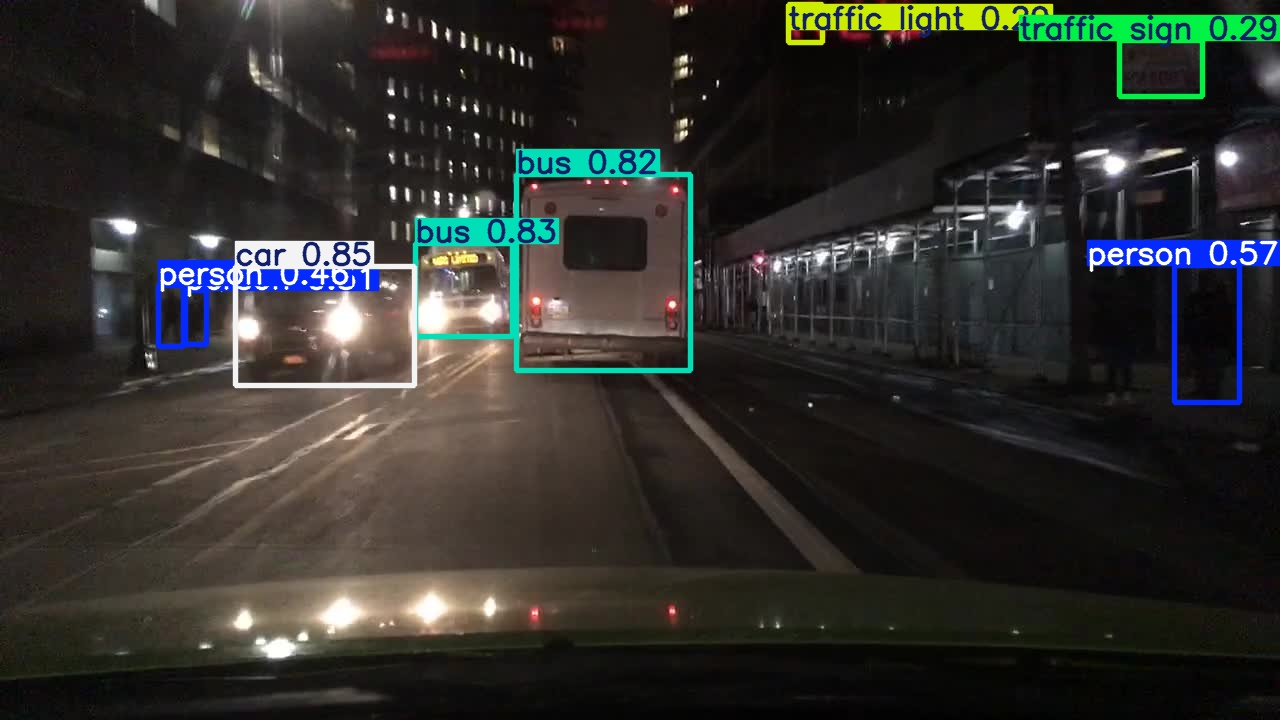

Найдено объектов: 8
  - car             (уверенность: 0.85)
  - bus             (уверенность: 0.83)
  - bus             (уверенность: 0.82)
  - person          (уверенность: 0.57)
  - person          (уверенность: 0.46)
  - person          (уверенность: 0.31)
  - traffic sign    (уверенность: 0.29)
  - traffic light   (уверенность: 0.29)


Изображение 4/6: cbdc7b52-013f6dd0.jpg

image 1/1 /kaggle/input/bdd100k-yolo/test/images/cbdc7b52-013f6dd0.jpg: 384x640 6 cars, 3 traffic signs, 6.9ms
Speed: 1.5ms preprocess, 6.9ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)


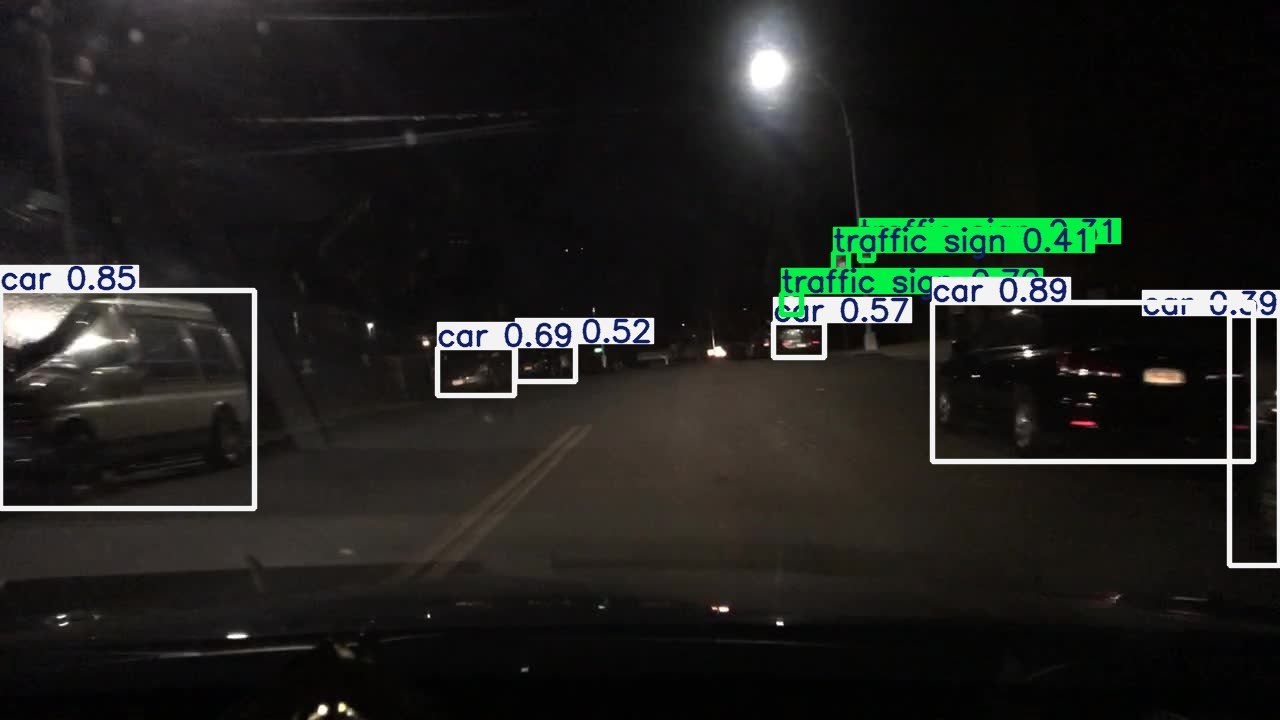

Найдено объектов: 9
  - car             (уверенность: 0.89)
  - car             (уверенность: 0.85)
  - traffic sign    (уверенность: 0.70)
  - car             (уверенность: 0.69)
  - car             (уверенность: 0.57)
  - car             (уверенность: 0.52)
  - traffic sign    (уверенность: 0.41)
  - car             (уверенность: 0.39)
  - traffic sign    (уверенность: 0.31)


Изображение 5/6: d28368e0-28bc5edf.jpg

image 1/1 /kaggle/input/bdd100k-yolo/test/images/d28368e0-28bc5edf.jpg: 384x640 5 cars, 1 truck, 1 traffic sign, 6.8ms
Speed: 1.2ms preprocess, 6.8ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


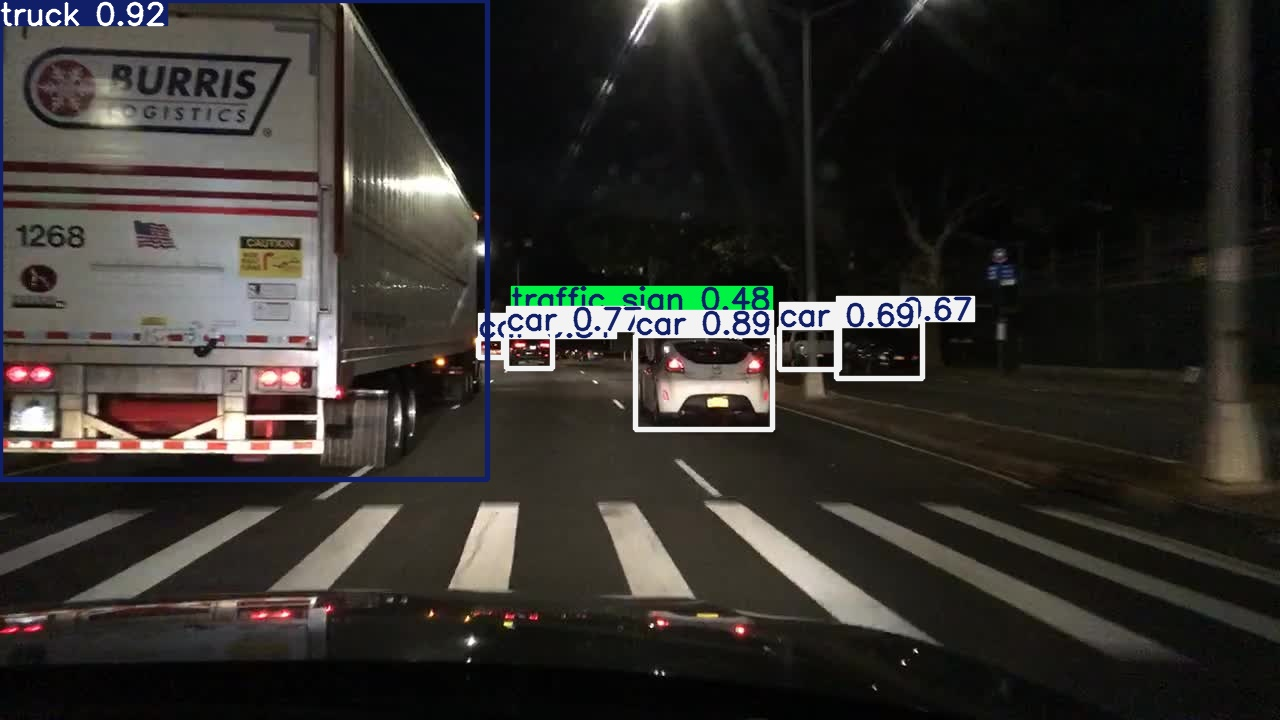

Найдено объектов: 7
  - truck           (уверенность: 0.92)
  - car             (уверенность: 0.89)
  - car             (уверенность: 0.77)
  - car             (уверенность: 0.69)
  - car             (уверенность: 0.67)
  - traffic sign    (уверенность: 0.48)
  - car             (уверенность: 0.31)


Изображение 6/6: e3b14ee0-5a1b29cd.jpg

image 1/1 /kaggle/input/bdd100k-yolo/test/images/e3b14ee0-5a1b29cd.jpg: 384x640 13 cars, 9 traffic lights, 1 traffic sign, 8.4ms
Speed: 1.7ms preprocess, 8.4ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


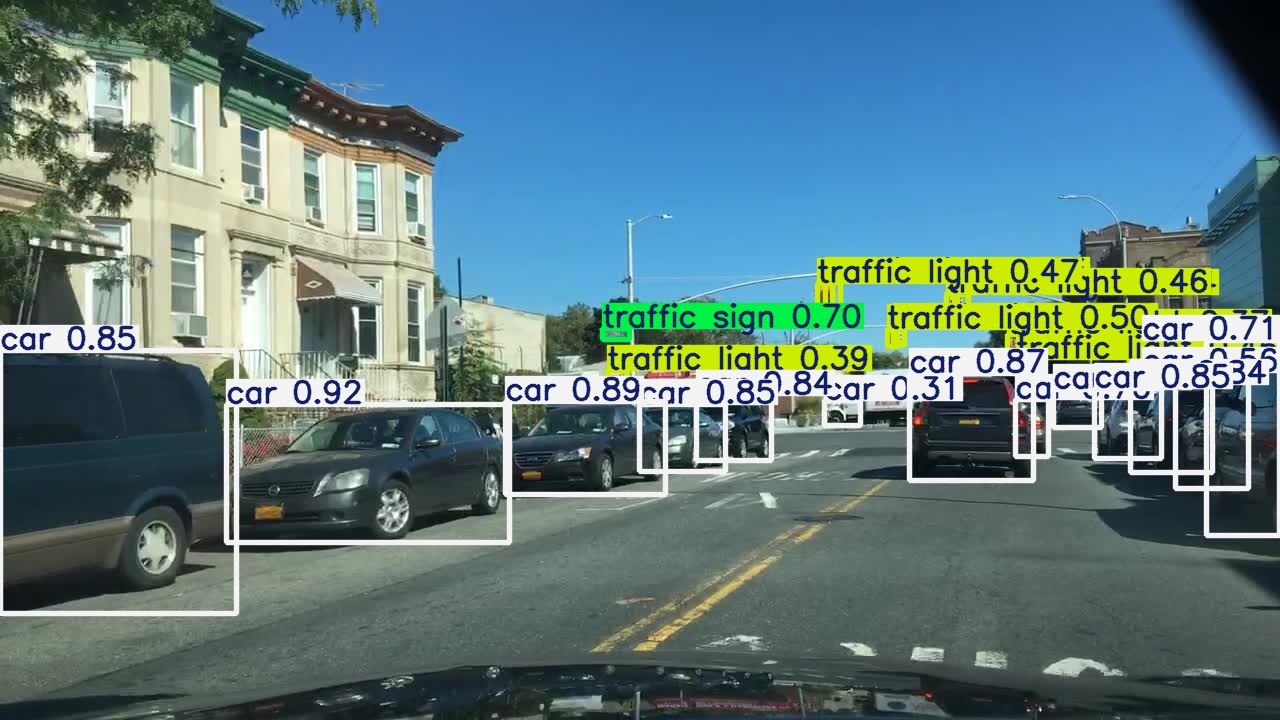

Найдено объектов: 23
  - car             (уверенность: 0.92)
  - car             (уверенность: 0.89)
  - car             (уверенность: 0.87)
  - car             (уверенность: 0.85)
  - car             (уверенность: 0.85)
  - car             (уверенность: 0.85)
  - car             (уверенность: 0.84)
  - car             (уверенность: 0.84)
  - car             (уверенность: 0.73)
  - car             (уверенность: 0.71)
  - car             (уверенность: 0.70)
  - traffic sign    (уверенность: 0.70)
  - car             (уверенность: 0.56)
  - traffic light   (уверенность: 0.50)
  - traffic light   (уверенность: 0.47)
  - traffic light   (уверенность: 0.46)
  - traffic light   (уверенность: 0.46)
  - traffic light   (уверенность: 0.39)
  - traffic light   (уверенность: 0.37)
  - traffic light   (уверенность: 0.34)
  - car             (уверенность: 0.31)
  - traffic light   (уверенность: 0.25)
  - traffic light   (уверенность: 0.25)




In [ ]:
# пути
path = kagglehub.dataset_download("a7madmostafa/bdd100k-yolo")
dataset_dir = os.path.join(path, "bdd100k_yolo") if os.path.exists(os.path.join(path, "bdd100k_yolo")) else path

# загружаем обученную модель
best_model_path = "/content/runs/detect/bdd_finetune-2/weights/best.pt"
model = YOLO(best_model_path)

# ищем папку с тестовыми картинками
test_images_path = os.path.join(dataset_dir, "test", "images")
if not os.path.exists(test_images_path) or len(os.listdir(test_images_path)) == 0:
    test_images_path = os.path.join(dataset_dir, "val", "images")
    print("Тестовая папка пуста или не найдена. Используем валидационные изображения.")

# Получаем список всех картинок и выбираем 6 случайных
all_images = [f for f in os.listdir(test_images_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
random_images = random.sample(all_images, 6)

for i, img_name in enumerate(random_images):
    img_path = os.path.join(test_images_path, img_name)
    print(f"Изображение {i+1}/6: {img_name}")

    # Запускаем предсказание
    results = model.predict(source=img_path, conf=0.25)

    # Сохраняем картинку с рамками
    output_filename = f"finetuned_result_{i+1}.jpg"
    results[0].save(filename=output_filename)

    # Выводим картинку
    display(Image(filename=output_filename, width=700))

    # Выводим список найденных объектов
    boxes = results[0].boxes
    if len(boxes) > 0:
        print(f"Найдено объектов: {len(boxes)}")
        for box in boxes:
            cls_id = int(box.cls[0])
            class_name = model.names[cls_id]
            confidence = float(box.conf[0])
            print(f"  - {class_name:<15} (уверенность: {confidence:.2f})")
    else:
        print("Объекты не найдены.")
    print("\n")

## Сравнение результатов работы

Using Colab cache for faster access to the 'bdd100k-yolo' dataset.
Загрузка моделей...
Сравнение предсказаний:

Изображение 1/2: ea52caee-e5e066ed.jpg


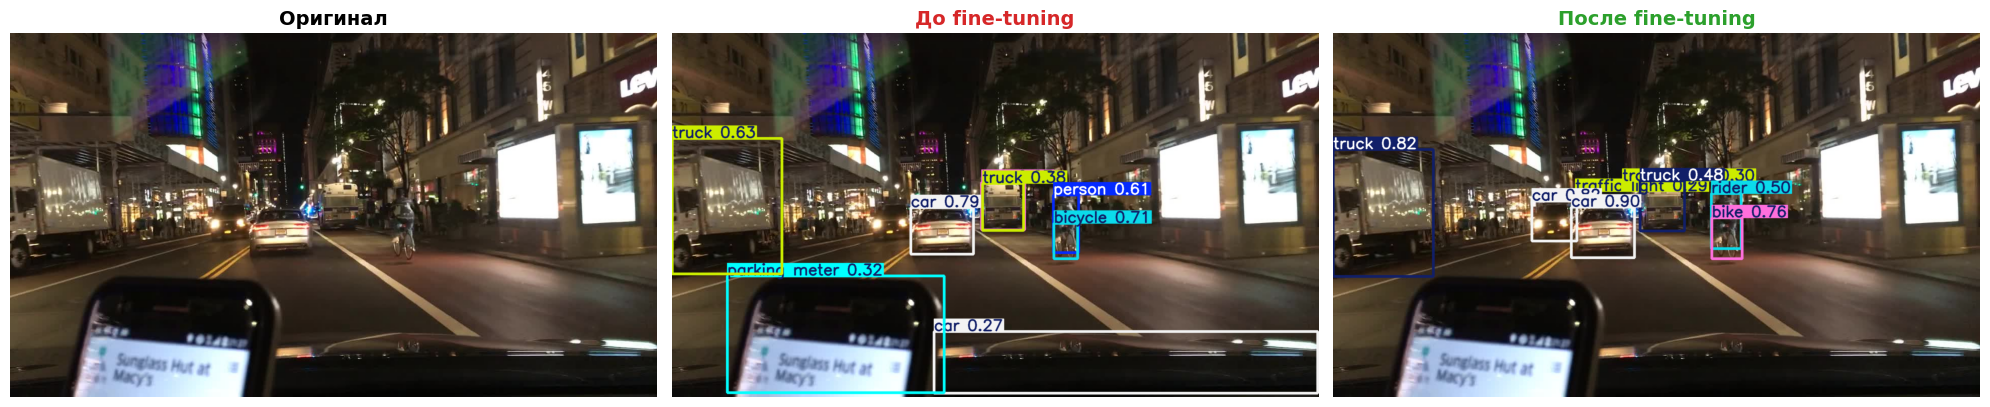

Изображение 2/2: f130ab0e-c400e4fd.jpg


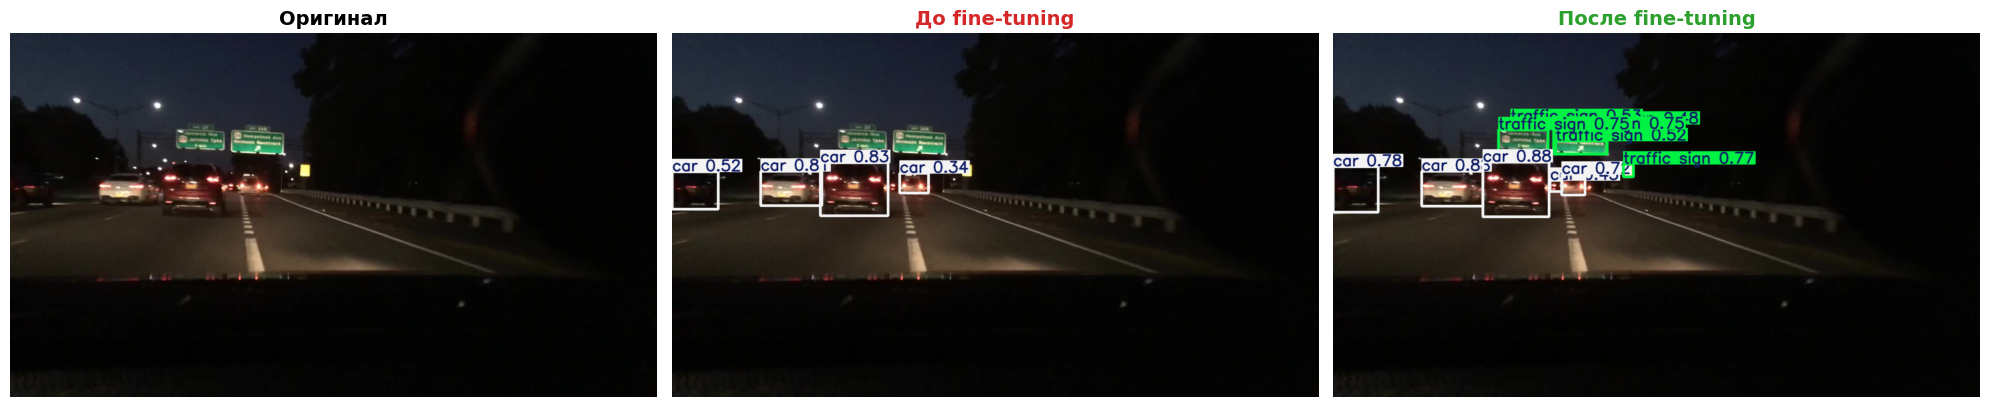

In [ ]:
# пути к датасету
path = kagglehub.dataset_download("a7madmostafa/bdd100k-yolo")
dataset_dir = os.path.join(path, "bdd100k_yolo") if os.path.exists(os.path.join(path, "bdd100k_yolo")) else path
test_images_path = os.path.join(dataset_dir, "test", "images")
if not os.path.exists(test_images_path) or len(os.listdir(test_images_path)) == 0:
    test_images_path = os.path.join(dataset_dir, "val", "images")

# загружаем обе модели
print("Загрузка моделей...")
model_pre = YOLO("yolov8n.pt")  # Базовая (COCO)
best_model_path = "/content/runs/detect/bdd_finetune-2/weights/best.pt"
model_fine = YOLO(best_model_path) # Дообученная (BDD100K)

# выбираем 2 случайные картинки
all_images = [f for f in os.listdir(test_images_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
random_images = random.sample(all_images, 2)

# функция для отрисовки
def plot_comparison(img_name):
    img_path = os.path.join(test_images_path, img_name)

    # Читаем оригинал
    original_img = cv2.imread(img_path)
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

    # Инференс предобученной модели
    res_pre = model_pre.predict(source=img_path, conf=0.25, verbose=False)[0]
    img_pre = res_pre.plot()
    img_pre = cv2.cvtColor(img_pre, cv2.COLOR_BGR2RGB)

    # Инференс дообученной модели
    res_fine = model_fine.predict(source=img_path, conf=0.25, verbose=False)[0]
    img_fine = res_fine.plot()
    img_fine = cv2.cvtColor(img_fine, cv2.COLOR_BGR2RGB)

    # Отрисовка
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))

    axes[0].imshow(original_img)
    axes[0].set_title("Оригинал", fontsize=14, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(img_pre)
    axes[1].set_title("До fine-tuning", fontsize=14, fontweight='bold', color='#d62728')
    axes[1].axis('off')

    axes[2].imshow(img_fine)
    axes[2].set_title("После fine-tuning", fontsize=14, fontweight='bold', color='#2ca02c')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

print("Сравнение предсказаний:\n")
for i, img_name in enumerate(random_images):
    print(f"Изображение {i+1}/2: {img_name}")
    plot_comparison(img_name)

Как можно заметить, после fine-tuning модель лучше распознает объекты (например, на 2 изображении он распознает дорожные знаки), а также "уверенность" на каждой рамке становится выше или же остается прежней. Также на обученной модели на 1 изображении ушло ошибочное определение телефона в класс "parking meter".

Загрузка моделей...
 Расчет метрик для До fine-tuning
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 77.8±12.3 MB/s, size: 68.3 KB)
val: Scanning /kaggle/input/bdd100k-yolo/val/labels... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000 306.4it/s 32.6s
WARNING ⚠️ val: Cache directory /kaggle/input/bdd100k-yolo/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 625/625 7.5it/s 1:23
                   all      10000     185578      0.125      0.078     0.0858     0.0455
Speed: 0.8ms preprocess, 2.2ms inference, 0.0ms loss, 1.9ms postprocess per image
 Расчет метрик для После fine-tuning
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,

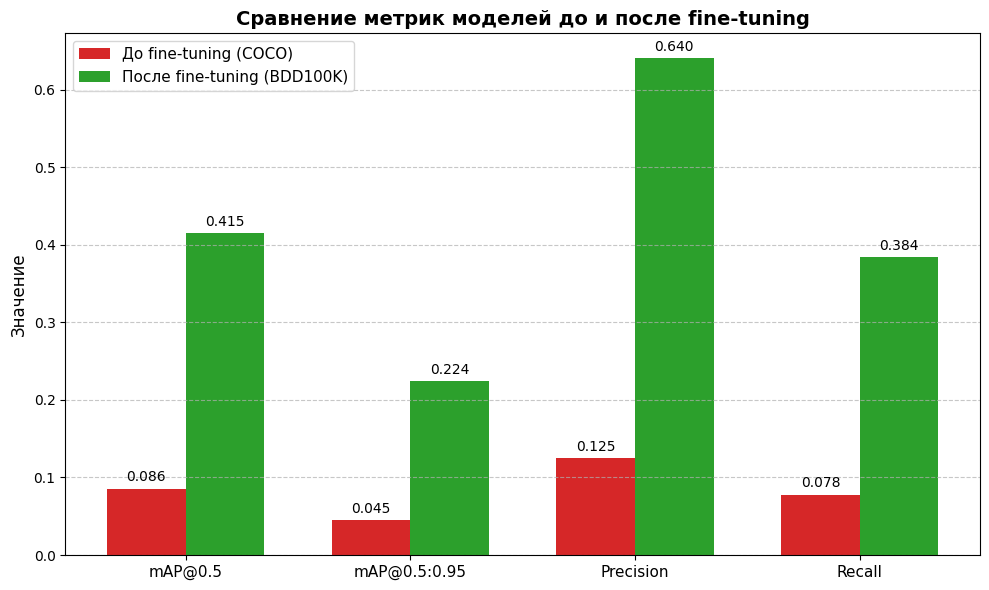

In [ ]:
print("Загрузка моделей...")
model_pre = YOLO("yolov8n.pt")
best_model_path = "/content/runs/detect/bdd_finetune-2/weights/best.pt"
model_fine = YOLO(best_model_path)

# функция получения метрик
def get_metrics(model, model_name):
    print(f" Расчет метрик для {model_name}")
    try:
        # запускаем валидацию
        metrics = model.val(data=yaml_path, verbose=False, plots=False)

        return {
            "mAP@0.5": metrics.box.map50,
            "mAP@0.5:0.95": metrics.box.map,
            "Precision": metrics.box.mp,
            "Recall": metrics.box.mr
        }
    except Exception as e:
        print(f"Ошибка при валидации {model_name}: {e}")
        return {"mAP@0.5": 0, "mAP@0.5:0.95": 0, "Precision": 0, "Recall": 0}

# метрики для обеих моделей
metrics_pre = get_metrics(model_pre, "До fine-tuning")
metrics_fine = get_metrics(model_fine, "После fine-tuning")

# текстовая таблица
print("\n" + "="*60)
print(f"{'Метрика':<20} | {'До fine-tuning':<15} | {'После fine-tuning':<15}")
print("-" * 60)
for key in metrics_pre.keys():
    print(f"{key:<20} | {metrics_pre[key]:<15.4f} | {metrics_fine[key]:<15.4f}")
print("="*60 + "\n")

# построение столбчатой диаграммы
labels = list(metrics_pre.keys())
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, list(metrics_pre.values()), width, label='До fine-tuning (COCO)', color='#d62728')
rects2 = ax.bar(x + width/2, list(metrics_fine.values()), width, label='После fine-tuning (BDD100K)', color='#2ca02c')

# Оформление графика
ax.set_ylabel('Значение', fontsize=12)
ax.set_title('Сравнение метрик моделей до и после fine-tuning', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Добавление значений над столбцами
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig("metrics_comparison.png", bbox_inches='tight')
plt.show()

## Контрольные вопросы

**Вопросы**


---


*Чем one-stage детекторы отличаются от two-stage?*

Одноэтапные (one-stage) детекторы предсказывают координаты рамок (bounding boxes) и классы объектов сразу за один проход нейросети, тогда как двухэтапные (two-stage) детекторы сначала генерируют гипотезы о расположении объектов, а затем классифицируют и уточняют каждую из них.

То есть главное противостояние между этими видами детектеров в скорости против точности.


one-stage: высокая скорость работы; в большинстве случаев точность ниже, чем у
two-stage;один проход сети; нет этапа генерации кандидатов.


two-stage: низкая/средняя скорость работы; точность выше, чем у one-stage; генерирует кандидатов, после чего уточняет их; треботельность к ресурсам.

---



*Какие ошибки чаще всего допускает модель при детекции?*


Модели детекции объектов чаще всего допускают ошибки четырёх основных типов:
1. ошибки локализации (верно определен класс, неточно отрисована рамка),
2. ошибки классификации (точно определены границы, неверно определен класс),
3. ложные срабатывания (детектор находит несуществующий объект там, где его нет, принимая текстуры фона, тени или блики за целевой класс),
4. пропуски объектов (проигнорирован объект в кадре).


